#import packages

In [ ]:
# Cell 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from imblearn.combine import SMOTEENN

import joblib
import warnings

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


# Cell 2: Define CDC File Paths and Required Field Positions

In [ ]:
# Cell 2: Define CDC File Paths and Required Field Positions

numerator_file = "/content/drive/MyDrive/mini project dataset/VS2022LINK.Public.USNUMPUB_R2024_08_07"

denominator_file = "/content/drive/MyDrive/mini project dataset/VS2022LINK.Public.USDENPUB_add_Seq_for2022Cohort_r2024_11_20"

# CDC fixed-width positions
# Python uses 0-based indexing, so subtract 1 from the CDC positions.

field_positions = {
    "co_seqnum": (364, 371),
    "mother_age": (74, 76),
    "education": (123, 124),
    "prenatal_visits": (237, 239),
    "cigarettes": (252, 254),
    "bmi": (282, 286),
    "pre_diabetes": (312, 313),
    "gest_diabetes": (313, 314),
    "pre_hypertension": (314, 315),
    "gest_hypertension": (315, 316),
    "apgar5": (443, 445),
    "plurality": (453, 454),
    "infant_sex": (474, 475),
    "gestational_age": (489, 491),
    "birth_weight": (511, 515)
}

print("File paths and field positions defined successfully.")

File paths and field positions defined successfully.


# Cell 3: Extract co_seqnum from Numerator File

In [ ]:
# Cell 3: Extract co_seqnum from Numerator File

numerator_seq = set()

with open(numerator_file, "r", errors="ignore") as f:
    for line in f:
        # CDC position 365-371 -> Python 364:371
        seq = line[364:371].strip()

        if seq:
            numerator_seq.add(seq)

print("Number of unique numerator co_seqnum values:", len(numerator_seq))

Number of unique numerator co_seqnum values: 20334


# Cell 4: Correct CDC Fixed-Width Field Positions



In [ ]:
# Cell 4: Correct CDC Fixed-Width Field Positions

field_positions = {
    "co_seqnum": (364, 371),          # CDC positions 365-371

    "mother_age": (74, 76),           # 75-76
    "education": (123, 124),          # 124
    "prenatal_visits": (237, 239),    # 238-239
    "cigarettes": (252, 254),         # 253-254
    "bmi": (282, 286),                # 283-286

    "pre_diabetes": (312, 313),       # 313
    "gest_diabetes": (313, 314),      # 314
    "pre_hypertension": (314, 315),  # 315
    "gest_hypertension": (315, 316), # 316

    "apgar5": (443, 445),             # 444-445
    "plurality": (453, 454),          # 454
    "infant_sex": (474, 475),         # 475
    "gestational_age": (489, 491),    # 490-491
    "birth_weight": (511, 515)        # 512-515
}

print("Corrected CDC field positions.")

Corrected CDC field positions.


# Cell 7: Inspect denominator record structure

In [ ]:
# Cell 7: Inspect denominator record structure

with open(denominator_file, "r", errors="ignore") as f:
    for i in range(3):
        line = f.readline()

        print(f"\nRecord {i+1}")
        print("Length:", len(line.rstrip("\n")))
        print("First 100 characters:", repr(line[:100]))
        print("Characters around position 365:", repr(line[350:390]))
        print("Last 100 characters:", repr(line[-100:]))


Record 1
Length: 1346
First 100 characters: '        202201    12187        21                2                        37116    1                '
Characters around position 365: '111      NN 11                  NNNNNN11'
Last 100 characters: '                                                                                  222222222 222222 \n'

Record 2
Length: 1346
First 100 characters: '        202201    15257        31                2                        27094    1                '
Characters around position 365: '111      NN 11                  NNNNNN11'
Last 100 characters: '                                                                                  422222222 222222 \n'

Record 3
Length: 1346
First 100 characters: '        202201    05392        31                2                        25094    1                '
Characters around position 365: '111      NN 11                  NNNNNN11'
Last 100 characters: '                                                           

# Cell 8: Inspect all non-empty fields near the end of the denominator record

In [ ]:
# Cell 8: Inspect all non-empty fields near the end of the denominator record

with open(denominator_file, "r", errors="ignore") as f:
    line = f.readline().rstrip("\n")

print("Total record length:", len(line))

# Print positions containing non-space characters in the last part
for start in range(1000, len(line), 50):
    end = min(start + 50, len(line))
    section = line[start:end]

    print(f"\nPositions {start+1}-{end}:")
    print(repr(section))

Total record length: 1346

Positions 1001-1050:
'                                                  '

Positions 1051-1100:
'                                                  '

Positions 1101-1150:
'                                                  '

Positions 1151-1200:
'                                                  '

Positions 1201-1250:
'                                                  '

Positions 1251-1300:
'                                                  '

Positions 1301-1346:
'                             222222222 222222 '


# Cell 9: Show all non-space character ranges

In [ ]:
# Cell 9: Show all non-space character ranges

line = line.rstrip()

in_field = False
start = None

for i, ch in enumerate(line):
    if ch != " " and not in_field:
        start = i
        in_field = True
    elif ch == " " and in_field:
        print(f"Positions {start+1}-{i}: {repr(line[start:i])}")
        in_field = False

if in_field:
    print(f"Positions {start+1}-{len(line)}: {repr(line[start:])}")

Positions 9-14: '202201'
Positions 19-23: '12187'
Positions 32-33: '21'
Positions 50-50: '2'
Positions 75-79: '37116'
Positions 84-84: '1'
Positions 104-109: '101101'
Positions 112-112: '0'
Positions 115-117: '011'
Positions 119-120: 'X1'
Positions 123-124: '16'
Positions 126-126: '1'
Positions 147-155: '400701101'
Positions 159-163: '00115'
Positions 165-165: '1'
Positions 171-176: '000000'
Positions 179-179: '1'
Positions 182-182: '1'
Positions 198-202: '88888'
Positions 206-210: '88888'
Positions 214-218: '88888'
Positions 224-227: '0713'
Positions 238-239: '10'
Positions 242-244: '061'
Positions 251-270: 'N10000000000001111N1'
Positions 280-287: '67125.83'
Positions 292-295: '1651'
Positions 299-301: '999'
Positions 303-307: '19991'
Positions 313-333: 'NNNNNN111111NXX111N00'
Positions 335-337: '111'
Positions 343-353: 'NNNNN111111'
Positions 360-361: 'NN'
Positions 363-364: '11'
Positions 383-395: 'NNNNNN1111111'
Positions 401-409: '11X111111'
Positions 415-419: 'NNNNN'
Positions 4

# Cell 10: Find where a known co_seqnum appears in the denominator

In [ ]:
# Cell 10: Find where a known co_seqnum appears in the denominator

# Take a few sequence numbers already extracted from numerator
sample_seqs = list(numerator_seq)[:5]

print("Sample numerator co_seqnum values:")
print(sample_seqs)

found = False

with open(denominator_file, "r", errors="ignore") as f:
    for line_number, line in enumerate(f, start=1):

        for seq in sample_seqs:
            if seq in line:
                positions = []
                start = 0

                while True:
                    pos = line.find(seq, start)

                    if pos == -1:
                        break

                    positions.append(pos + 1)   # Convert to 1-based position
                    start = pos + 1

                print("\nMATCH FOUND")
                print("Denominator record:", line_number)
                print("co_seqnum:", seq)
                print("Positions:", positions)

                for pos in positions:
                    print(
                        "Around position",
                        pos,
                        ":",
                        repr(line[max(0, pos-11):pos+10])
                    )

                found = True
                break

        if found:
            break

if not found:
    print("\nNo sample co_seqnum was found in the denominator file.")

Sample numerator co_seqnum values:
['0020038', '0019644', '0019287', '0010533', '0002507']

MATCH FOUND
Denominator record: 1662427
co_seqnum: 0010533
Positions: [365]
Around position 365 : '     NN 1100105332022'


# Cell 11: Inspect denominator record for added co_seqnum

In [ ]:
# Cell 11: Inspect denominator record for added co_seqnum

with open(denominator_file, "r", errors="ignore") as f:
    for i in range(5):
        line = f.readline().rstrip("\n")

        print(f"\nRecord {i+1}")
        print("Length:", len(line))

        # Show the complete non-space fields with positions
        in_field = False
        start = None

        for j, ch in enumerate(line):
            if ch != " " and not in_field:
                start = j
                in_field = True

            elif ch == " " and in_field:
                print(f"{start+1:4d}-{j:4d}: {line[start:j]}")
                in_field = False

        if in_field:
            print(f"{start+1:4d}-{len(line):4d}: {line[start:]}")


Record 1
Length: 1346
   9-  14: 202201
  19-  23: 12187
  32-  33: 21
  50-  50: 2
  75-  79: 37116
  84-  84: 1
 104- 109: 101101
 112- 112: 0
 115- 117: 011
 119- 120: X1
 123- 124: 16
 126- 126: 1
 147- 155: 400701101
 159- 163: 00115
 165- 165: 1
 171- 176: 000000
 179- 179: 1
 182- 182: 1
 198- 202: 88888
 206- 210: 88888
 214- 218: 88888
 224- 227: 0713
 238- 239: 10
 242- 244: 061
 251- 270: N10000000000001111N1
 280- 287: 67125.83
 292- 295: 1651
 299- 301: 999
 303- 307: 19991
 313- 333: NNNNNN111111NXX111N00
 335- 337: 111
 343- 353: NNNNN111111
 360- 361: NN
 363- 364: 11
 383- 395: NNNNNN1111111
 401- 409: 11X111111
 415- 419: NNNNN
 421- 425: 11111
 427- 427: 1
 433- 438: 4N2211
 444- 450: 1041885
 454- 454: 1
 459- 459: 9
 475- 475: F
 477- 478: 03
 481- 484: 2021
 490- 494: 42102
 499- 503: 41092
 509- 515: 0933203
 517- 522: NNNNNN
 524- 529: 111111
 531- 531: 1
 537- 561: NNNNNN111111NNNNNN1111111
 567- 570: NYY1
1330-1338: 222222222
1340-1345: 222222

Record 2
Lengt

# Cell 12: Construct the complete linked dataset

In [ ]:
# Cell 12: Construct the complete linked dataset

import pandas as pd
import os

output_file = "/content/drive/MyDrive/mini project dataset/infant_mortality_14_features.csv"

# Confirmed CDC positions (Python zero-based slicing)
field_positions = {
    "co_seqnum": (364, 371),
    "mother_age": (74, 76),
    "education": (123, 124),
    "prenatal_visits": (237, 239),
    "cigarettes": (252, 254),
    "bmi": (282, 286),
    "pre_diabetes": (312, 313),
    "gest_diabetes": (313, 314),
    "pre_hypertension": (314, 315),
    "gest_hypertension": (315, 316),
    "apgar5": (443, 445),
    "plurality": (453, 454),
    "infant_sex": (474, 475),
    "gestational_age": (489, 491),
    "birth_weight": (511, 515)
}

columns = [
    "co_seqnum",
    "mother_age",
    "education",
    "prenatal_visits",
    "cigarettes",
    "bmi",
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension",
    "apgar5",
    "plurality",
    "infant_sex",
    "gestational_age",
    "birth_weight",
    "infant_death"
]

# --------------------------------------------------
# Step 1: Get death record sequence numbers
# --------------------------------------------------

numerator_seq = set()

with open(numerator_file, "r", errors="ignore") as f:
    for line in f:
        seq = line[364:371].strip()

        if seq:
            numerator_seq.add(seq)

print("Unique numerator co_seqnum:", len(numerator_seq))


# --------------------------------------------------
# Step 2: Process denominator file line-by-line
# --------------------------------------------------

if os.path.exists(output_file):
    os.remove(output_file)

chunk = []
chunk_size = 100000

total_records = 0
death_records = 0

with open(denominator_file, "r", errors="ignore") as f:

    for line in f:

        seq = line[364:371].strip()

        # Do not skip records because of an empty sequence number.
        # Every denominator record must be retained.
        if not seq:
            seq = ""

        values = []

        for field in columns[:-1]:
            start, end = field_positions[field]
            values.append(line[start:end].strip())

        # 1 = infant death, 0 = infant survival
        infant_death = 1 if seq in numerator_seq else 0

        values.append(infant_death)

        chunk.append(values)

        total_records += 1

        if infant_death == 1:
            death_records += 1

        # Save every 100,000 records
        if len(chunk) >= chunk_size:

            df_chunk = pd.DataFrame(chunk, columns=columns)

            df_chunk.to_csv(
                output_file,
                mode="a",
                index=False,
                header=not os.path.exists(output_file)
            )

            chunk.clear()

            print(
                f"Processed: {total_records:,} | "
                f"Deaths: {death_records:,} | "
                f"Survival: {total_records - death_records:,}"
            )


# --------------------------------------------------
# Step 3: Save remaining records
# --------------------------------------------------

if chunk:

    df_chunk = pd.DataFrame(chunk, columns=columns)

    df_chunk.to_csv(
        output_file,
        mode="a",
        index=False,
        header=not os.path.exists(output_file)
    )


# --------------------------------------------------
# Step 4: Final summary
# --------------------------------------------------

print("\nDataset construction completed.")
print("Total records:", f"{total_records:,}")
print("Infant death records:", f"{death_records:,}")
print("Infant survival records:", f"{total_records - death_records:,}")
print("Saved to:", output_file)

Unique numerator co_seqnum: 20334
Processed: 100,000 | Deaths: 676 | Survival: 99,324
Processed: 200,000 | Deaths: 1,209 | Survival: 198,791
Processed: 300,000 | Deaths: 1,612 | Survival: 298,388
Processed: 400,000 | Deaths: 2,017 | Survival: 397,983
Processed: 500,000 | Deaths: 2,445 | Survival: 497,555
Processed: 600,000 | Deaths: 2,823 | Survival: 597,177
Processed: 700,000 | Deaths: 3,282 | Survival: 696,718
Processed: 800,000 | Deaths: 3,902 | Survival: 796,098
Processed: 900,000 | Deaths: 4,532 | Survival: 895,468
Processed: 1,000,000 | Deaths: 5,180 | Survival: 994,820
Processed: 1,100,000 | Deaths: 5,831 | Survival: 1,094,169
Processed: 1,200,000 | Deaths: 6,331 | Survival: 1,193,669
Processed: 1,300,000 | Deaths: 6,936 | Survival: 1,293,064
Processed: 1,400,000 | Deaths: 7,551 | Survival: 1,392,449
Processed: 1,500,000 | Deaths: 8,153 | Survival: 1,491,847
Processed: 1,600,000 | Deaths: 8,571 | Survival: 1,591,429
Processed: 1,700,000 | Deaths: 9,179 | Survival: 1,690,821
Proc

# Cell 13: Verify the constructed dataset

In [ ]:
# Cell 13: Verify the constructed dataset

import pandas as pd

dataset_file = "/content/drive/MyDrive/mini project dataset/infant_mortality_14_features.csv"

df = pd.read_csv(dataset_file, nrows=10)

print("Columns:")
print(df.columns.tolist())

print("\nNumber of columns:", len(df.columns))

print("\nFirst 10 records:")
display(df)

print("\nData types:")
print(df.dtypes)

Columns:
['co_seqnum', 'mother_age', 'education', 'prenatal_visits', 'cigarettes', 'bmi', 'pre_diabetes', 'gest_diabetes', 'pre_hypertension', 'gest_hypertension', 'apgar5', 'plurality', 'infant_sex', 'gestational_age', 'birth_weight', 'infant_death']

Number of columns: 16

First 10 records:


,co_seqnum,mother_age,education,prenatal_visits,cigarettes,bmi,pre_diabetes,gest_diabetes,pre_hypertension,gest_hypertension,apgar5,plurality,infant_sex,gestational_age,birth_weight,infant_death
0,NaN,37,6,10,0,25.8,N,N,N,N,10,1,F,42,3203,0
1,NaN,27,3,3,0,20.4,N,N,N,N,9,1,M,38,3090,0
2,NaN,25,5,9,0,19.0,N,N,N,N,9,1,F,37,2523,0
3,NaN,42,7,10,0,22.1,N,N,N,N,10,1,F,38,4139,0
4,NaN,27,3,17,5,26.6,N,N,N,Y,9,1,M,37,3000,0
5,NaN,22,3,8,0,27.3,N,N,N,N,9,1,M,37,3540,0
6,NaN,35,6,17,0,39.2,N,Y,Y,N,9,1,M,39,4450,0
7,NaN,20,3,19,0,35.2,N,Y,N,N,9,1,F,41,3630,0
8,NaN,37,8,8,0,24.9,N,N,N,N,9,1,F,39,2800,0
9,NaN,37,4,8,10,31.7,N,N,Y,N,9,1,M,26,2615,0



Data types:
co_seqnum            float64
mother_age             int64
education              int64
prenatal_visits        int64
cigarettes             int64
bmi                  float64
pre_diabetes          object
gest_diabetes         object
pre_hypertension      object
gest_hypertension     object
apgar5                 int64
plurality              int64
infant_sex            object
gestational_age        int64
birth_weight           int64
infant_death           int64
dtype: object


# Cell 14: Load the complete dataset for ML


In [ ]:
# Cell 14: Load the complete dataset for ML

import pandas as pd

dataset_file = "/content/drive/MyDrive/mini project dataset/infant_mortality_14_features.csv"

ml_columns = [
    "mother_age",
    "education",
    "prenatal_visits",
    "cigarettes",
    "bmi",
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension",
    "apgar5",
    "plurality",
    "infant_sex",
    "gestational_age",
    "birth_weight",
    "infant_death"
]

df = pd.read_csv(
    dataset_file,
    usecols=ml_columns
)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nTarget distribution:")
print(df["infant_death"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (3676029, 15)

Columns:
['mother_age', 'education', 'prenatal_visits', 'cigarettes', 'bmi', 'pre_diabetes', 'gest_diabetes', 'pre_hypertension', 'gest_hypertension', 'apgar5', 'plurality', 'infant_sex', 'gestational_age', 'birth_weight', 'infant_death']

First 5 records:


,mother_age,education,prenatal_visits,cigarettes,bmi,pre_diabetes,gest_diabetes,pre_hypertension,gest_hypertension,apgar5,plurality,infant_sex,gestational_age,birth_weight,infant_death
0,37,6,10,0,25.8,N,N,N,N,10,1,F,42,3203,0
1,27,3,3,0,20.4,N,N,N,N,9,1,M,38,3090,0
2,25,5,9,0,19.0,N,N,N,N,9,1,F,37,2523,0
3,42,7,10,0,22.1,N,N,N,N,10,1,F,38,4139,0
4,27,3,17,5,26.6,N,N,N,Y,9,1,M,37,3000,0



Target distribution:
infant_death
0    3655730
1      20299
Name: count, dtype: int64

Missing values:
mother_age           0
education            0
prenatal_visits      0
cigarettes           0
bmi                  0
pre_diabetes         0
gest_diabetes        0
pre_hypertension     0
gest_hypertension    0
apgar5               0
plurality            0
infant_sex           0
gestational_age      0
birth_weight         0
infant_death         0
dtype: int64


# Cell 15: Check numerical feature values

In [ ]:
# Cell 15: Check numerical feature values

numerical_columns = [
    "mother_age",
    "education",
    "prenatal_visits",
    "cigarettes",
    "bmi",
    "apgar5",
    "plurality",
    "gestational_age",
    "birth_weight"
]

for col in numerical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().sort_index().head(20))


--- mother_age ---
mother_age
12        77
13       316
14      1435
15      4513
16     10231
17     20724
18     39388
19     69135
20     92654
21    111703
22    130714
23    145008
24    159567
25    174699
26    189234
27    205124
28    218454
29    228301
30    235489
31    240338
Name: count, dtype: int64

--- education ---
education
1    118427
2    286025
3    958997
4    650928
5    307718
6    798813
7    381012
8    112420
9     61689
Name: count, dtype: int64

--- prenatal_visits ---
prenatal_visits
0      77878
1      21508
2      34094
3      41322
4      57814
5      81777
6     112341
7     144524
8     229991
9     269561
10    503796
11    396393
12    538945
13    328962
14    253580
15    184601
16     97475
17     51690
18     41262
19     24799
Name: count, dtype: int64

--- cigarettes ---
cigarettes
0     3491644
1        6408
2        7140
3        8571
4        6733
5       18146
6        5045
7        3042
8        2629
9         598
10      44189
11      

# Cell 16: Check categorical feature values

In [ ]:
# Cell 16: Check categorical feature values

categorical_columns = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension",
    "infant_sex"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- pre_diabetes ---
pre_diabetes
N    3626406
Y      42836
U       6787
Name: count, dtype: int64

--- gest_diabetes ---
gest_diabetes
N    3372395
Y     296847
U       6787
Name: count, dtype: int64

--- pre_hypertension ---
pre_hypertension
N    3562391
Y     106851
U       6787
Name: count, dtype: int64

--- gest_hypertension ---
gest_hypertension
N    3320379
Y     348863
U       6787
Name: count, dtype: int64

--- infant_sex ---
infant_sex
M    1878719
F    1797310
Name: count, dtype: int64


#Cell 17 — Check ranges and unknown codes

In [ ]:
print("Maximum values:")
for col in numerical_columns:
    print(f"{col}: {df[col].max()}")

print("\nPotential unknown codes:")
print("education = 9:", (df["education"] == 9).sum())
print("apgar5 = 99:", (df["apgar5"] == 99).sum())
print("gestational_age = 99:", (df["gestational_age"] == 99).sum())
print("birth_weight = 9999:", (df["birth_weight"] == 9999).sum())

Maximum values:
mother_age: 50
education: 9
prenatal_visits: 99
cigarettes: 99
bmi: 99.9
apgar5: 99
plurality: 4
gestational_age: 99
birth_weight: 9999

Potential unknown codes:
education = 9: 61689
apgar5 = 99: 16248
gestational_age = 99: 2805
birth_weight = 9999: 1118


#Cell 18 — Convert unknown values to missing

In [ ]:
import numpy as np

unknown_codes = {
    "education": 9,
    "prenatal_visits": 99,
    "cigarettes": 99,
    "bmi": 99.9,
    "apgar5": 99,
    "gestational_age": 99,
    "birth_weight": 9999
}

for col, code in unknown_codes.items():
    df[col] = df[col].replace(code, np.nan)

print("Missing values after replacing unknown codes:")
print(df.isnull().sum())

Missing values after replacing unknown codes:
mother_age               0
education            61689
prenatal_visits      77764
cigarettes           15582
bmi                  76090
pre_diabetes             0
gest_diabetes            0
pre_hypertension         0
gest_hypertension        0
apgar5               16248
plurality                0
infant_sex               0
gestational_age       2805
birth_weight          1118
infant_death             0
dtype: int64


#Cell 19 — Encode disease columns

In [ ]:
disease_columns = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension"
]

for col in disease_columns:
    df[col] = df[col].replace({
        "Y": 1,
        "N": 0,
        "U": np.nan
    })

print("Disease columns after encoding:")
print(df[disease_columns].value_counts(dropna=False))

Disease columns after encoding:
pre_diabetes  gest_diabetes  pre_hypertension  gest_hypertension
0.0           0.0            0.0               0.0                  2954028
                                               1.0                   294667
              1.0            0.0               0.0                   233058
              0.0            1.0               0.0                    80864
              1.0            0.0               1.0                    46060
1.0           0.0            0.0               0.0                    26442
0.0           1.0            1.0               0.0                    17729
1.0           0.0            1.0               0.0                     8258
                             0.0               1.0                     8136
NaN           NaN            NaN               NaN                     6787
Name: count, dtype: int64


#Cell 20 — Encode infant sex

In [ ]:
df["infant_sex"] = df["infant_sex"].replace({
    "M": 1,
    "F": 0
})

print(df["infant_sex"].value_counts(dropna=False))

infant_sex
1    1878719
0    1797310
Name: count, dtype: int64


#Cell 21 — Check all remaining missing values

In [ ]:
print("Remaining missing values:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Remaining missing values:
mother_age               0
education            61689
prenatal_visits      77764
cigarettes           15582
bmi                  76090
pre_diabetes          6787
gest_diabetes         6787
pre_hypertension      6787
gest_hypertension     6787
apgar5               16248
plurality                0
infant_sex               0
gestational_age       2805
birth_weight          1118
infant_death             0
dtype: int64

Total missing values:
278444


#Cell 22 — Median Imputation

In [ ]:
imputation_columns = [
    "mother_age",
    "education",
    "prenatal_visits",
    "cigarettes",
    "bmi",
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension",
    "apgar5",
    "plurality",
    "infant_sex",
    "gestational_age",
    "birth_weight"
]

for col in imputation_columns:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after median imputation:")
print(df.isnull().sum())

Missing values after median imputation:
mother_age           0
education            0
prenatal_visits      0
cigarettes           0
bmi                  0
pre_diabetes         0
gest_diabetes        0
pre_hypertension     0
gest_hypertension    0
apgar5               0
plurality            0
infant_sex           0
gestational_age      0
birth_weight         0
infant_death         0
dtype: int64


In [ ]:
# Cell 22A: Convert the imputed education values back to integer type

df["education"] = df["education"].astype(int)

print("Education data type:", df["education"].dtype)
print("\nEducation values:")
print(df["education"].value_counts().sort_index())

Education data type: int64

Education values:
education
1    118427
2    286025
3    958997
4    712617
5    307718
6    798813
7    381012
8    112420
Name: count, dtype: int64


#Cell 23 — Verify the cleaned dataset

In [ ]:
print("Dataset shape:", df.shape)

print("\nTotal missing values:",
      df.isnull().sum().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (3676029, 15)

Total missing values: 0

Data types:
mother_age             int64
education              int64
prenatal_visits      float64
cigarettes           float64
bmi                  float64
pre_diabetes         float64
gest_diabetes        float64
pre_hypertension     float64
gest_hypertension    float64
apgar5               float64
plurality              int64
infant_sex             int64
gestational_age      float64
birth_weight         float64
infant_death           int64
dtype: object


#REDUCED EXPERIMENT

In [ ]:
import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/mini project dataset/infant_mortality_14_features.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print(df["infant_death"].value_counts())

KeyboardInterrupt: 

In [ ]:
# Separate survival and death records
survival_df = df[df["infant_death"] == 0]
death_df = df[df["infant_death"] == 1]

# Select 200,000 random survival records
survival_sample = survival_df.sample(
    n=45000,
    random_state=42
)

# Combine all death records with the selected survival records
df_200k = pd.concat(
    [survival_sample, death_df],
    ignore_index=True
)

# Shuffle the combined dataset
df_200k = df_200k.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("New dataset shape:", df_200k.shape)
print("\nClass distribution:")
print(df_200k["infant_death"].value_counts())

print("\nClass percentages:")
print(df_200k["infant_death"].value_counts(normalize=True) * 100)

New dataset shape: (65299, 16)

Class distribution:
infant_death
0    45000
1    20299
Name: count, dtype: int64

Class percentages:
infant_death
0    68.913766
1    31.086234
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_200k.drop(columns=["infant_death"])
y = df_200k["infant_death"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training shape: (52239, 15)
Testing shape : (13060, 15)

Training class distribution:
infant_death
0    36000
1    16239
Name: count, dtype: int64

Testing class distribution:
infant_death
0    9000
1    4060
Name: count, dtype: int64


In [ ]:
print("Columns:")
print(X_train.columns.tolist())

print("\nData types:")
print(X_train.dtypes)

print("\nMissing values in training data:")
print(X_train.isnull().sum())

Columns:
['co_seqnum', 'mother_age', 'education', 'prenatal_visits', 'cigarettes', 'bmi', 'pre_diabetes', 'gest_diabetes', 'pre_hypertension', 'gest_hypertension', 'apgar5', 'plurality', 'infant_sex', 'gestational_age', 'birth_weight']

Data types:
co_seqnum            float64
mother_age             int64
education              int64
prenatal_visits        int64
cigarettes             int64
bmi                  float64
pre_diabetes          object
gest_diabetes         object
pre_hypertension      object
gest_hypertension     object
apgar5                 int64
plurality              int64
infant_sex            object
gestational_age        int64
birth_weight           int64
dtype: object

Missing values in training data:
co_seqnum            36000
mother_age               0
education                0
prenatal_visits          0
cigarettes               0
bmi                      0
pre_diabetes             0
gest_diabetes            0
pre_hypertension         0
gest_hypertension        

In [ ]:
# Drop identifier column
X_train = X_train.drop(columns=["co_seqnum"])
X_test = X_test.drop(columns=["co_seqnum"])

# Convert disease-related columns: Y = 1, N = 0
disease_columns = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension"
]

for col in disease_columns:
    X_train[col] = X_train[col].map({"Y": 1, "N": 0})
    X_test[col] = X_test[col].map({"Y": 1, "N": 0})

# Convert infant sex: M = 1, F = 0
X_train["infant_sex"] = X_train["infant_sex"].map({"M": 1, "F": 0})
X_test["infant_sex"] = X_test["infant_sex"].map({"M": 1, "F": 0})

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nTraining data types:")
print(X_train.dtypes)

print("\nMissing values:")
print(X_train.isnull().sum())

Training shape: (52239, 14)
Testing shape : (13060, 14)

Training data types:
mother_age             int64
education              int64
prenatal_visits        int64
cigarettes             int64
bmi                  float64
pre_diabetes         float64
gest_diabetes        float64
pre_hypertension     float64
gest_hypertension    float64
apgar5                 int64
plurality              int64
infant_sex             int64
gestational_age        int64
birth_weight           int64
dtype: object

Missing values:
mother_age             0
education              0
prenatal_visits        0
cigarettes             0
bmi                    0
pre_diabetes         171
gest_diabetes        171
pre_hypertension     171
gest_hypertension    171
apgar5                 0
plurality              0
infant_sex             0
gestational_age        0
birth_weight           0
dtype: int64


In [ ]:
# Calculate medians from training data only
train_medians = X_train[disease_columns].median()

# Fill missing values in training and testing data
X_train[disease_columns] = X_train[disease_columns].fillna(train_medians)
X_test[disease_columns] = X_test[disease_columns].fillna(train_medians)

print("Missing values after imputation:")
print(X_train.isnull().sum())

print("\nTotal missing values in training:", X_train.isnull().sum().sum())
print("Total missing values in testing :", X_test.isnull().sum().sum())

Missing values after imputation:
mother_age           0
education            0
prenatal_visits      0
cigarettes           0
bmi                  0
pre_diabetes         0
gest_diabetes        0
pre_hypertension     0
gest_hypertension    0
apgar5               0
plurality            0
infant_sex           0
gestational_age      0
birth_weight         0
dtype: int64

Total missing values in training: 0
Total missing values in testing : 0


In [ ]:
from xgboost import XGBClassifier

# Calculate class weight from training data
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative samples:", negative)
print("Positive samples:", positive)
print("Scale positive weight:", scale_pos_weight)

# XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train, y_train)

print("\nXGBoost training completed.")

Negative samples: 36000
Positive samples: 16239
Scale positive weight: 2.2168852761869573

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Training predictions
y_train_pred = xgb_model.predict(X_train)
y_train_prob = xgb_model.predict_proba(X_train)[:, 1]

# Testing predictions
y_test_pred = xgb_model.predict(X_test)
y_test_prob = xgb_model.predict_proba(X_test)[:, 1]

# Training metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred)
train_recall = recall_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_auc = roc_auc_score(y_train, y_train_prob)

# Testing metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_prob)

print("TRAINING PERFORMANCE")
print("-" * 42)
print(f"Accuracy : {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall   : {train_recall:.4f}")
print(f"F1-score : {train_f1:.4f}")
print(f"ROC-AUC  : {train_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

print("\nTESTING PERFORMANCE")
print("-" * 42)
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

TRAINING PERFORMANCE
------------------------------------------
Accuracy : 0.8757
Precision: 0.8156
Recall   : 0.7756
F1-score : 0.7951
ROC-AUC  : 0.9255

Confusion Matrix:
[[33152  2848]
 [ 3644 12595]]

TESTING PERFORMANCE
------------------------------------------
Accuracy : 0.8596
Precision: 0.7851
Recall   : 0.7549
F1-score : 0.7697
ROC-AUC  : 0.9076

Confusion Matrix:
[[8161  839]
 [ 995 3065]]


#Train & Test smote

In [ ]:
import pandas as pd
import numpy as np

# Separate features and target
X = df.drop(columns=["infant_death", "co_seqnum"], errors="ignore").copy()
y = df["infant_death"].copy()

# Convert maternal disease columns
disease_cols = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension"
]

for col in disease_cols:
    X[col] = X[col].replace({
        "Y": 1, "N": 0, "U": np.nan
    })
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Convert infant sex
X["infant_sex"] = X["infant_sex"].replace({
    "M": 1, "F": 0
})
X["infant_sex"] = pd.to_numeric(
    X["infant_sex"], errors="coerce"
)

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nNon-numeric columns:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Dataset shape: (3676029, 14)

Target distribution:
infant_death
0    3655730
1      20299
Name: count, dtype: int64

Non-numeric columns:
[]


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nTraining classes:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

Training shape: (2940823, 14)
Testing shape : (735206, 14)

Training classes:
infant_death
0    2924584
1      16239
Name: count, dtype: int64

Testing classes:
infant_death
0    731146
1      4060
Name: count, dtype: int64


In [ ]:
for col in X_train.columns:
    median_value = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

print("Training missing values:", X_train.isna().sum().sum())
print("Testing missing values :", X_test.isna().sum().sum())

Training missing values: 0
Testing missing values : 0


In [ ]:
from imblearn.over_sampling import SMOTE

smote_train = SMOTE(
    sampling_strategy={1: 100_000},
    random_state=42
)

X_train_smote, y_train_smote = smote_train.fit_resample(
    X_train, y_train
)

print("Training after SMOTE:")
print(y_train_smote.value_counts())
print("Training shape:", X_train_smote.shape)

Training after SMOTE:
infant_death
0    2924584
1     100000
Name: count, dtype: int64
Training shape: (3024584, 14)


In [ ]:
smote_test = SMOTE(
    sampling_strategy={1: 100_000},
    random_state=42
)

X_test_smote, y_test_smote = smote_test.fit_resample(
    X_test, y_test
)

print("Testing after SMOTE:")
print(y_test_smote.value_counts())
print("Testing shape:", X_test_smote.shape)

Testing after SMOTE:
infant_death
0    731146
1    100000
Name: count, dtype: int64
Testing shape: (831146, 14)


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_smote, y_train_smote)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Training predictions
y_train_pred = xgb_model.predict(X_train_smote)
y_train_prob = xgb_model.predict_proba(X_train_smote)[:, 1]

# Testing predictions
y_test_pred = xgb_model.predict(X_test_smote)
y_test_prob = xgb_model.predict_proba(X_test_smote)[:, 1]


def evaluate_model(y_true, y_pred, y_prob, name):
    print(f"\n{name}")
    print("-" * 45)
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall   : {recall_score(y_true, y_pred):.4f}")
    print(f"F1-score : {f1_score(y_true, y_pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_true, y_prob):.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))


evaluate_model(
    y_train_smote, y_train_pred, y_train_prob,
    "TRAINING PERFORMANCE — SMOTE TRAIN"
)

evaluate_model(
    y_test_smote, y_test_pred, y_test_prob,
    "TESTING PERFORMANCE — SMOTE TEST"
)


TRAINING PERFORMANCE — SMOTE TRAIN
---------------------------------------------
Accuracy : 0.9947
Precision: 0.9726
Recall   : 0.8638
F1-score : 0.9150
ROC-AUC  : 0.9840
Confusion Matrix:
[[2922146    2438]
 [  13616   86384]]

TESTING PERFORMANCE — SMOTE TEST
---------------------------------------------
Accuracy : 0.9923
Precision: 0.9930
Recall   : 0.9423
F1-score : 0.9670
ROC-AUC  : 0.9949
Confusion Matrix:
[[730479    667]
 [  5769  94231]]


#Smote full

In [ ]:
from imblearn.over_sampling import SMOTE

# Prepare features and target
X = df.drop(
    columns=["infant_death", "co_seqnum"],
    errors="ignore"
).copy()

y = df["infant_death"].copy()

# Convert categorical columns to numeric
disease_cols = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension"
]

for col in disease_cols:
    X[col] = X[col].replace({
        "Y": 1,
        "N": 0,
        "U": np.nan
    })
    X[col] = pd.to_numeric(X[col], errors="coerce")

X["infant_sex"] = X["infant_sex"].replace({
    "M": 1,
    "F": 0
})
X["infant_sex"] = pd.to_numeric(
    X["infant_sex"], errors="coerce"
)

# Handle missing values
for col in X.columns:
    X[col] = X[col].fillna(X[col].median())

# Apply SMOTE to the entire dataset
smote = SMOTE(
    sampling_strategy={1: 900_000},
    random_state=42
)

X_smote, y_smote = smote.fit_resample(X, y)

print("Resampled dataset:", X_smote.shape)
print("\nClass distribution:")
print(y_smote.value_counts())

Resampled dataset: (4555730, 14)

Class distribution:
infant_death
0    3655730
1     900000
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_smote,
    y_smote,
    test_size=0.20,
    stratify=y_smote,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nTraining classes:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

Training shape: (3644584, 14)
Testing shape : (911146, 14)

Training classes:
infant_death
0    2924584
1     720000
Name: count, dtype: int64

Testing classes:
infant_death
0    731146
1    180000
Name: count, dtype: int64


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Training predictions
y_train_pred = xgb_model.predict(X_train)
y_train_prob = xgb_model.predict_proba(X_train)[:, 1]

# Testing predictions
y_test_pred = xgb_model.predict(X_test)
y_test_prob = xgb_model.predict_proba(X_test)[:, 1]


def evaluate_model(y_true, y_pred, y_prob, title):
    print(f"\n{title}")
    print("-" * 45)

    print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall   : {recall_score(y_true, y_pred):.4f}")
    print(f"F1-score : {f1_score(y_true, y_pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_true, y_prob):.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))


evaluate_model(
    y_train, y_train_pred, y_train_prob,
    "TRAINING PERFORMANCE — WHOLE-DATASET SMOTE"
)

evaluate_model(
    y_test, y_test_pred, y_test_prob,
    "TESTING PERFORMANCE — WHOLE-DATASET SMOTE"
)


TRAINING PERFORMANCE — WHOLE-DATASET SMOTE
---------------------------------------------
Accuracy : 0.9845
Precision: 0.9831
Recall   : 0.9379
F1-score : 0.9599
ROC-AUC  : 0.9952

Confusion Matrix:
[[2912956   11628]
 [  44726  675274]]

TESTING PERFORMANCE — WHOLE-DATASET SMOTE
---------------------------------------------
Accuracy : 0.9845
Precision: 0.9827
Recall   : 0.9381
F1-score : 0.9598
ROC-AUC  : 0.9950

Confusion Matrix:
[[728171   2975]
 [ 11151 168849]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")


Random Forest training completed.


In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

def evaluate_model(y_true, y_pred, y_prob, title):
    print(f"\n{title}")
    print("-" * 45)
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall   : {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1-score : {f1_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_true, y_prob):.4f}")
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# Training performance
rf_train_pred = rf_model.predict(X_train)
rf_train_prob = rf_model.predict_proba(X_train)[:, 1]

# Testing performance
rf_test_pred = rf_model.predict(X_test)
rf_test_prob = rf_model.predict_proba(X_test)[:, 1]

evaluate_model(
    y_train, rf_train_pred, rf_train_prob,
    "RANDOM FOREST - TRAINING PERFORMANCE"
)

evaluate_model(
    y_test, rf_test_pred, rf_test_prob,
    "RANDOM FOREST - TESTING PERFORMANCE"
)



RANDOM FOREST - TRAINING PERFORMANCE
---------------------------------------------
Accuracy : 0.9855
Precision: 0.9892
Recall   : 0.9370
F1-score : 0.9624
ROC-AUC  : 0.9983

Confusion Matrix:
[[2917209    7375]
 [  45346  674654]]

RANDOM FOREST - TESTING PERFORMANCE
---------------------------------------------
Accuracy : 0.9841
Precision: 0.9862
Recall   : 0.9325
F1-score : 0.9586
ROC-AUC  : 0.9969

Confusion Matrix:
[[728803   2343]
 [ 12143 167857]]


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(
    max_iter=300,
    solver="saga",
    random_state=42,
    n_jobs=-1
)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed.")


Logistic Regression training completed.


In [ ]:

# Training predictions
lr_train_pred = lr_model.predict(X_train_scaled)
lr_train_prob = lr_model.predict_proba(X_train_scaled)[:, 1]

# Testing predictions
lr_test_pred = lr_model.predict(X_test_scaled)
lr_test_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

evaluate_model(
    y_train, lr_train_pred, lr_train_prob,
    "LOGISTIC REGRESSION - TRAINING PERFORMANCE"
)

evaluate_model(
    y_test, lr_test_pred, lr_test_prob,
    "LOGISTIC REGRESSION - TESTING PERFORMANCE"
)



LOGISTIC REGRESSION - TRAINING PERFORMANCE
---------------------------------------------
Accuracy : 0.9103
Precision: 0.8919
Recall   : 0.6210
F1-score : 0.7322
ROC-AUC  : 0.9149

Confusion Matrix:
[[2870365   54219]
 [ 272867  447133]]

LOGISTIC REGRESSION - TESTING PERFORMANCE
---------------------------------------------
Accuracy : 0.9106
Precision: 0.8923
Recall   : 0.6227
F1-score : 0.7335
ROC-AUC  : 0.9143

Confusion Matrix:
[[717623  13523]
 [ 67919 112081]]


In [ ]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models = {
    "XGBoost": (xgb_model, X_train, X_test),
    "Random Forest": (rf_model, X_train, X_test),
    "Logistic Regression": (lr_model, X_train_scaled, X_test_scaled)
}

results = []

for name, (model, Xtr, Xte) in models.items():
    train_pred = model.predict(Xtr)
    test_pred = model.predict(Xte)

    train_prob = model.predict_proba(Xtr)[:, 1]
    test_prob = model.predict_proba(Xte)[:, 1]

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred, zero_division=0),
        "Test Precision": precision_score(y_test, test_pred, zero_division=0),
        "Train Recall": recall_score(y_train, train_pred, zero_division=0),
        "Test Recall": recall_score(y_test, test_pred, zero_division=0),
        "Train F1": f1_score(y_train, train_pred, zero_division=0),
        "Test F1": f1_score(y_test, test_pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, test_prob)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))


              Model  Train Accuracy  Test Accuracy  Train Precision  Test Precision  Train Recall  Test Recall  Train F1  Test F1  Test ROC-AUC
            XGBoost          0.9845         0.9845           0.9831          0.9827        0.9379       0.9380    0.9599   0.9598        0.9950
      Random Forest          0.9855         0.9841           0.9892          0.9862        0.9370       0.9325    0.9624   0.9586        0.9969
Logistic Regression          0.9103         0.9106           0.8919          0.8923        0.6210       0.6227    0.7322   0.7335        0.9143


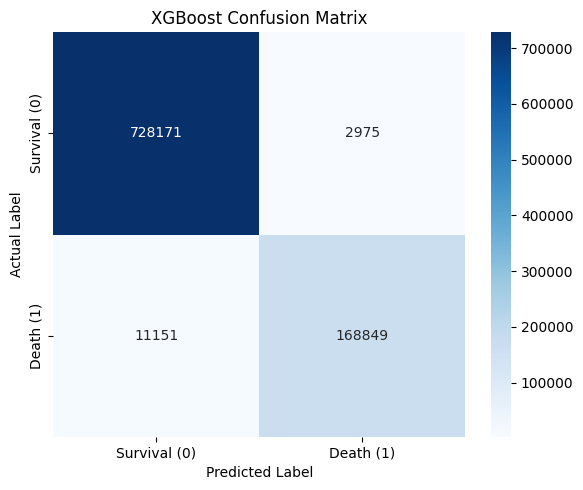

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_test_pred_xgb = xgb_model.predict(X_test)

cm = confusion_matrix(y_test, y_test_pred_xgb)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Survival (0)", "Death (1)"],
    yticklabels=["Survival (0)", "Death (1)"]
)
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

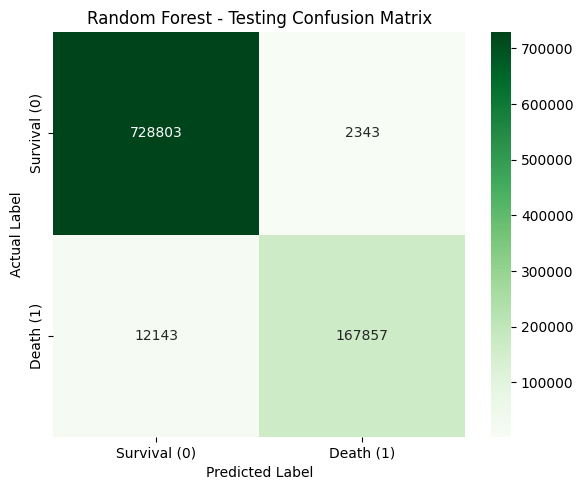

In [ ]:
y_test_pred_rf = rf_model.predict(X_test)

cm = confusion_matrix(y_test, y_test_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=["Survival (0)", "Death (1)"],
    yticklabels=["Survival (0)", "Death (1)"]
)
plt.title("Random Forest - Testing Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

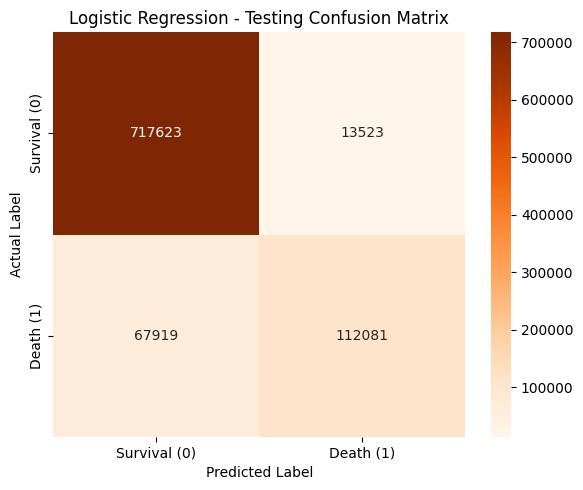

In [ ]:
y_test_pred_lr = lr_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_test_pred_lr)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Oranges",
    xticklabels=["Survival (0)", "Death (1)"],
    yticklabels=["Survival (0)", "Death (1)"]
)
plt.title("Logistic Regression - Testing Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

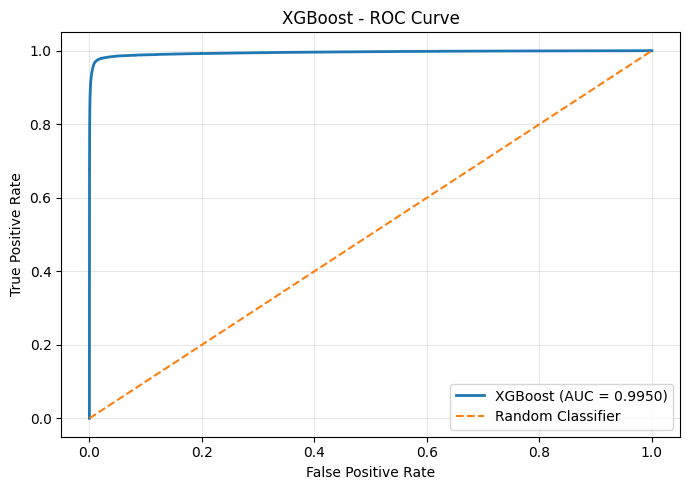

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Predicted probabilities
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# ROC curve
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
auc_xgb = roc_auc_score(y_test, y_prob_xgb)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr_xgb, tpr_xgb,
    label=f"XGBoost (AUC = {auc_xgb:.4f})",
    linewidth=2
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


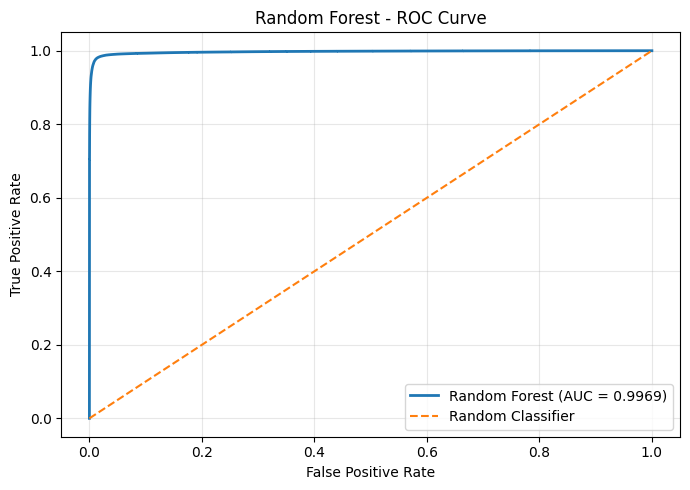

In [ ]:

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr_rf, tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.4f})",
    linewidth=2
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


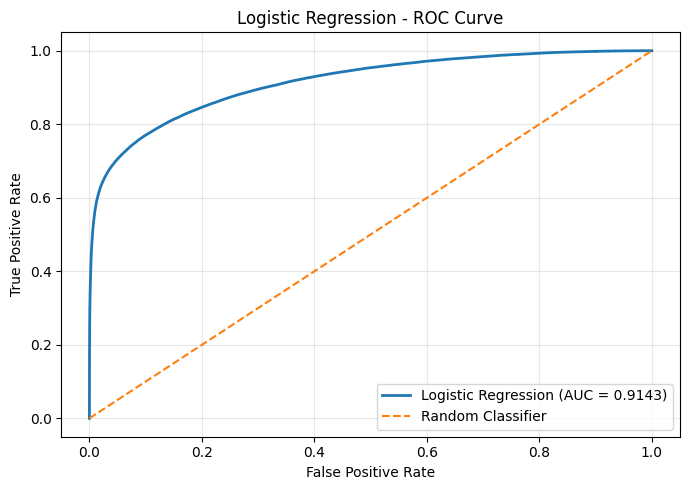

In [ ]:

y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr_lr, tpr_lr,
    label=f"Logistic Regression (AUC = {auc_lr:.4f})",
    linewidth=2
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
import joblib
import os

model_path = "/content/drive/MyDrive/mini project dataset"

os.makedirs(model_path, exist_ok=True)

joblib.dump(
    xgb_model,
    os.path.join(model_path, "xgboost_infant_mortality.pkl")
)

joblib.dump(
    list(X_train.columns),
    os.path.join(model_path, "infant_mortality_features.pkl")
)

print("XGBoost model and feature list saved successfully.")

XGBoost model and feature list saved successfully.


In [ ]:
import os, random, joblib
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

folder = "/content/drive/MyDrive/mini project dataset"

model = joblib.load(os.path.join(folder, "xgboost_infant_mortality.pkl"))
prep = joblib.load(os.path.join(folder, "xgb_preprocessing.pkl"))

# Sample 100,000 eligible births from the unseen denominator
rng = random.Random(42)
sample = []
eligible = 0
sample_size = 100_000

with open(denominator_path, "rb") as f:
    for line in f:
        line = line.rstrip(b"\r\n")

        if len(line) != 1346:
            continue

        status = line[103:104]
        if not status or status >= b"4":
            continue

        eligible += 1

        if len(sample) < sample_size:
            sample.append(line)
        else:
            j = rng.randrange(eligible)
            if j < sample_size:
                sample[j] = line

print("Eligible births scanned:", eligible)
print("Sample size:", len(sample))

def num(raw):
    raw = raw.strip()
    if not raw or not raw.isdigit():
        return np.nan
    return float(raw)

def get_disease(raw):
    value = raw.decode("ascii", errors="ignore").strip()
    return prep["disease_mapping"].get(value, np.nan)

rows, labels = [], []

for line in sample:
    bmi_raw = num(line[282:286])
    bmi = bmi_raw / 10 if not np.isnan(bmi_raw) else np.nan

    seq = line[364:371].strip()
    year = line[371:375].strip()
    label = int(bool(seq and year and (seq, year) in death_keys))

    rows.append({
        "mother_age": num(line[74:76]),
        "education": num(line[123:125]),
        "prenatal_visits": num(line[237:239]),
        "cigarettes": num(line[252:254]),
        "bmi": bmi,
        "pre_diabetes": get_disease(line[312:313]),
        "gest_diabetes": get_disease(line[313:314]),
        "pre_hypertension": get_disease(line[314:315]),
        "gest_hypertension": get_disease(line[315:316]),
        "apgar5": num(line[443:445]),
        "plurality": num(line[453:454]),
        "infant_sex": prep["sex_mapping"].get(
            line[474:475].decode("ascii", errors="ignore").strip(),
            np.nan
        ),
        "gestational_age": num(line[489:491]),
        "birth_weight": num(line[511:515]),
    })
    labels.append(label)

X = pd.DataFrame(rows)[prep["feature_columns"]]
y_true = np.array(labels)

# Convert the documented unknown codes to missing values
for col, code in prep["unknown_codes"].items():
    X.loc[X[col] == code, col] = np.nan

# Use the saved training medians
X = X.fillna(prep["median_values"])
X = X.astype(float)

# Predict with the saved model
y_pred = model.predict(X).astype(int)
y_prob = model.predict_proba(X)[:, 1]

print("\nActual label counts:")
print(pd.Series(y_true).value_counts().sort_index().rename(
    index={0: "No linked death in available file", 1: "Linked death"}
))

print("\nAccuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))

if len(np.unique(y_true)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
else:
    print("ROC-AUC unavailable: sample contains only one class.")

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    target_names=["No linked death", "Linked death"],
    zero_division=0
))

Eligible births scanned: 3596017
Sample size: 100000

Actual label counts:
No linked death in available file    99545
Linked death                           455
Name: count, dtype: int64

Accuracy: 0.9941
Precision: 0.4
Recall: 0.5714
F1-score: 0.4706
ROC-AUC: 0.9169

Confusion matrix:
[[99155   390]
 [  195   260]]

Classification report:
                 precision    recall  f1-score   support

No linked death       1.00      1.00      1.00     99545
   Linked death       0.40      0.57      0.47       455

       accuracy                           0.99    100000
      macro avg       0.70      0.78      0.73    100000
   weighted avg       1.00      0.99      0.99    100000



In [ ]:
import random
import numpy as np
import pandas as pd
import joblib
import os

folder = "/content/drive/MyDrive/mini project dataset"
model = joblib.load(os.path.join(folder, "xgboost_infant_mortality.pkl"))

# Separate records using the available linked-death labels
class0, class1 = [], []

for line in sample:
    seq = line[364:371].strip()
    year = line[371:375].strip()
    actual = int(bool(seq and year and (seq, year) in death_keys))

    if actual == 1 and len(class1) < 4:
        class1.append(line)
    elif actual == 0 and len(class0) < 4:
        class0.append(line)

print("Class 0 found:", len(class0))
print("Class 1 found:", len(class1))

if len(class0) < 4 or len(class1) < 4:
    print("The existing sample lacks enough examples. We need to sample more records.")
else:
    selected = class0 + class1
    random.Random(42).shuffle(selected)

    rows, actual_labels = [], []

    for line in selected:
        bmi_raw = num(line[282:286])
        bmi = bmi_raw / 10 if not np.isnan(bmi_raw) else np.nan

        seq = line[364:371].strip()
        year = line[371:375].strip()
        actual = int(bool(seq and year and (seq, year) in death_keys))

        rows.append({
            "mother_age": num(line[74:76]),
            "education": num(line[123:125]),
            "prenatal_visits": num(line[237:239]),
            "cigarettes": num(line[252:254]),
            "bmi": bmi,
            "pre_diabetes": get_disease(line[312:313]),
            "gest_diabetes": get_disease(line[313:314]),
            "pre_hypertension": get_disease(line[314:315]),
            "gest_hypertension": get_disease(line[315:316]),
            "apgar5": num(line[443:445]),
            "plurality": num(line[453:454]),
            "infant_sex": prep["sex_mapping"].get(
                line[474:475].decode("ascii", errors="ignore").strip(),
                np.nan
            ),
            "gestational_age": num(line[489:491]),
            "birth_weight": num(line[511:515]),
        })
        actual_labels.append(actual)

    X8 = pd.DataFrame(rows)[prep["feature_columns"]]

    for col, code in prep["unknown_codes"].items():
        X8.loc[X8[col] == code, col] = np.nan

    X8 = X8.fillna(prep["median_values"]).astype(float)

    pred = model.predict(X8).astype(int)
    prob = model.predict_proba(X8)[:, 1]

    results = pd.DataFrame({
        "Instance": range(1, 9),
        "Actual_Label": actual_labels,
        "Predicted_Label": pred,
        "Death_Probability_%": np.round(prob * 100, 2)
    })

    print("\nActual class counts:")
    print(results["Actual_Label"].value_counts().sort_index())
    print("\nPredictions:")
    print(results.to_string(index=False))

Class 0 found: 4
Class 1 found: 4

Actual class counts:
Actual_Label
0    4
1    4
Name: count, dtype: int64

Predictions:
 Instance  Actual_Label  Predicted_Label  Death_Probability_%
        1             0                0             0.340000
        2             1                0             3.420000
        3             1                1            99.320000
        4             1                1            55.720001
        5             0                0             0.300000
        6             1                1            78.959999
        7             0                0             1.190000
        8             0                0             0.540000


In [ ]:
# Generate the exact unseen-data table for the report

import numpy as np
import pandas as pd

report_rows = []

for i, line in enumerate(selected):
    seq = line[364:371].strip()
    year = line[371:375].strip()

    actual = int(bool(seq and year and (seq, year) in death_keys))

    # Corrected BMI extraction
    bmi_raw = line[282:286].decode("ascii", errors="replace").strip()

    try:
        bmi = float(bmi_raw)
    except (ValueError, TypeError):
        bmi = np.nan

    row = {
        "Instance": i + 1,
        "mother_age": num(line[74:76]),
        "education": num(line[123:125]),
        "prenatal_visits": num(line[237:239]),
        "cigarettes": num(line[252:254]),
        "bmi": bmi,
        "pre_diabetes": get_disease(line[312:313]),
        "gest_diabetes": get_disease(line[313:314]),
        "pre_hypertension": get_disease(line[314:315]),
        "gest_hypertension": get_disease(line[315:316]),
        "apgar5": num(line[443:445]),
        "plurality": num(line[453:454]),
        "infant_sex": prep["sex_mapping"].get(
            line[474:475].decode("ascii", errors="ignore").strip(),
            np.nan
        ),
        "gestational_age": num(line[489:491]),
        "birth_weight": num(line[511:515]),
        "Actual_Label": actual
    }

    report_rows.append(row)

# Preserve extracted values for the report
report_df = pd.DataFrame(report_rows)

# Apply the model's preprocessing
X_report = report_df[prep["feature_columns"]].copy()

for col, code in prep["unknown_codes"].items():
    X_report.loc[X_report[col] == code, col] = np.nan

X_model = X_report.fillna(prep["median_values"]).astype(float)

# Generate predictions
report_df["Predicted_Label"] = model.predict(X_model).astype(int)

report_df["Death_Probability_%"] = np.round(
    model.predict_proba(X_model)[:, 1] * 100, 2
)

# Display the complete results
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

display(report_df)

# Verify class counts and missing BMI values
print("\nActual label counts:")
print(report_df["Actual_Label"].value_counts().sort_index())

print("\nMissing BMI values:", report_df["bmi"].isna().sum())

,Instance,mother_age,education,prenatal_visits,cigarettes,bmi,pre_diabetes,gest_diabetes,pre_hypertension,gest_hypertension,apgar5,plurality,infant_sex,gestational_age,birth_weight,Actual_Label,Predicted_Label,Death_Probability_%
0,1,31.0,6.0,15.0,0.0,33.2,0,0,1,0,9.0,1.0,0,40.0,3960.0,0,0,0.340000
1,2,41.0,3.0,8.0,20.0,39.6,0,0,0,0,9.0,1.0,0,39.0,3315.0,1,0,3.420000
2,3,30.0,3.0,4.0,0.0,20.5,0,0,0,0,1.0,1.0,0,21.0,395.0,1,1,99.300003
3,4,36.0,2.0,15.0,0.0,27.4,0,0,0,0,2.0,1.0,1,35.0,2980.0,1,1,55.720001
4,5,29.0,7.0,12.0,0.0,22.6,0,0,0,0,9.0,1.0,0,38.0,4180.0,0,0,0.310000
5,6,22.0,3.0,4.0,0.0,18.6,0,0,0,0,8.0,1.0,1,24.0,564.0,1,1,77.570000
6,7,37.0,5.0,11.0,0.0,24.9,0,0,0,0,9.0,1.0,0,38.0,3640.0,0,0,1.190000
7,8,33.0,7.0,10.0,0.0,24.6,0,0,0,0,9.0,1.0,0,38.0,2760.0,0,0,0.570000



Actual label counts:
Actual_Label
0    4
1    4
Name: count, dtype: int64

Missing BMI values: 0


In [ ]:
# Inspect the raw CDC record for Instance 1

line = selected[0]

print("Record length:", len(line))
print("\nRaw record section (positions 250–330):")
print(line[249:330].decode("ascii", errors="replace"))

print("\nIndividual character positions:")
for start in range(250, 331, 10):
    end = min(start + 10, 331)
    print(f"{start}-{end - 1}: {line[start - 1:end - 1].decode('ascii', errors='replace')}")

Record length: 1346

Raw record section (positions 250–330):
 N10000000000001111N1         69133.24    2251   264 13941     NNYNNN111111NXX111

Individual character positions:
250-259:  N10000000
260-269: 000001111N
270-279: 1         
280-289: 69133.24  
290-299:   2251   2
300-309: 64 13941  
310-319:    NNYNNN1
320-329: 11111NXX11
330-330: 1


In [ ]:
bmi_raw = num(line[282:286])
bmi = bmi_raw / 10 if not np.isnan(bmi_raw) else np.nan

In [ ]:
line = selected[0]

for pos in range(270, 311):
    print(f"Position {pos}: {chr(line[pos - 1])!r}")

Position 270: '1'
Position 271: ' '
Position 272: ' '
Position 273: ' '
Position 274: ' '
Position 275: ' '
Position 276: ' '
Position 277: ' '
Position 278: ' '
Position 279: ' '
Position 280: '6'
Position 281: '9'
Position 282: '1'
Position 283: '3'
Position 284: '3'
Position 285: '.'
Position 286: '2'
Position 287: '4'
Position 288: ' '
Position 289: ' '
Position 290: ' '
Position 291: ' '
Position 292: '2'
Position 293: '2'
Position 294: '5'
Position 295: '1'
Position 296: ' '
Position 297: ' '
Position 298: ' '
Position 299: '2'
Position 300: '6'
Position 301: '4'
Position 302: ' '
Position 303: '1'
Position 304: '3'
Position 305: '9'
Position 306: '4'
Position 307: '1'
Position 308: ' '
Position 309: ' '
Position 310: ' '


In [ ]:
line = selected[0]

raw_bmi = line[282:286].decode("ascii", errors="replace")

print("Raw BMI field:", repr(raw_bmi))
print("Direct float conversion:", float(raw_bmi))
print("Existing num() result:", num(line[282:286]))

Raw BMI field: '33.2'
Direct float conversion: 33.2
Existing num() result: nan


In [ ]:
# Correct BMI extraction
bmi_raw = line[281:285].decode("ascii", errors="replace").strip()

try:
    bmi = float(bmi_raw)
except (ValueError, TypeError):
    bmi = np.nan

print("Raw BMI:", repr(bmi_raw))
print("Extracted BMI:", bmi)

Raw BMI: '133.'
Extracted BMI: 133.0


In [ ]:
line = selected[0]

for start in range(275, 311):
    print(
        f"{start}-{start+3}: "
        f"{line[start:start+4].decode('ascii', errors='replace')!r}"
    )

275-278: '    '
276-279: '   6'
277-280: '  69'
278-281: ' 691'
279-282: '6913'
280-283: '9133'
281-284: '133.'
282-285: '33.2'
283-286: '3.24'
284-287: '.24 '
285-288: '24  '
286-289: '4   '
287-290: '    '
288-291: '   2'
289-292: '  22'
290-293: ' 225'
291-294: '2251'
292-295: '251 '
293-296: '51  '
294-297: '1   '
295-298: '   2'
296-299: '  26'
297-300: ' 264'
298-301: '264 '
299-302: '64 1'
300-303: '4 13'
301-304: ' 139'
302-305: '1394'
303-306: '3941'
304-307: '941 '
305-308: '41  '
306-309: '1   '
307-310: '    '
308-311: '    '
309-312: '   N'
310-313: '  NN'


In [ ]:
bmi_raw = line[282:286].decode("ascii", errors="replace").strip()

try:
    bmi = float(bmi_raw)
except (ValueError, TypeError):
    bmi = np.nan

print("Raw BMI:", repr(bmi_raw))
print("Extracted BMI:", bmi)

Raw BMI: '33.2'
Extracted BMI: 33.2


#new

In [ ]:
from sklearn.model_selection import train_test_split

# 80% development data, 20% final test data
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Split development data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    stratify=y_dev,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining classes:")
print(y_train.value_counts())

Training: (2352658, 14)
Validation: (588165, 14)
Testing: (735206, 14)

Training classes:
infant_death
0    2339667
1      12991
Name: count, dtype: int64


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy={1: 100_000},
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Training after SMOTE:", X_train_smote.shape)
print("\nClass distribution:")
print(y_train_smote.value_counts())

Training after SMOTE: (2439667, 14)

Class distribution:
infant_death
0    2339667
1     100000
Name: count, dtype: int64


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

configs = [
    {"max_depth": 3, "min_child_weight": 5,  "learning_rate": 0.05,
     "reg_alpha": 0, "reg_lambda": 5},
    {"max_depth": 3, "min_child_weight": 10, "learning_rate": 0.05,
     "reg_alpha": 1, "reg_lambda": 5},
    {"max_depth": 4, "min_child_weight": 5,  "learning_rate": 0.03,
     "reg_alpha": 1, "reg_lambda": 5},
    {"max_depth": 4, "min_child_weight": 10, "learning_rate": 0.03,
     "reg_alpha": 2, "reg_lambda": 10},
    {"max_depth": 5, "min_child_weight": 10, "learning_rate": 0.03,
     "reg_alpha": 2, "reg_lambda": 10}
]

results = []
models = []

for i, params in enumerate(configs, start=1):
    model = XGBClassifier(
        n_estimators=300,
        max_depth=params["max_depth"],
        min_child_weight=params["min_child_weight"],
        learning_rate=params["learning_rate"],
        reg_alpha=params["reg_alpha"],
        reg_lambda=params["reg_lambda"],
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_smote, y_train_smote)

    # Keep threshold fixed at 0.50
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": i,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1-score": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob),
        **params
    })

    models.append(model)

results_df = pd.DataFrame(results).sort_values(
    "F1-score", ascending=False
)

print(results_df.round(4).to_string(index=False))

 Model  Accuracy  Precision  Recall  F1-score  ROC-AUC  max_depth  min_child_weight  learning_rate  reg_alpha  reg_lambda
     2    0.9951     0.5820  0.3910    0.4678   0.8881          3                10           0.05          1           5
     3    0.9950     0.5697  0.3950    0.4665   0.8909          4                 5           0.03          1           5
     5    0.9952     0.5945  0.3836    0.4663   0.8920          5                10           0.03          2          10
     4    0.9950     0.5761  0.3916    0.4663   0.8905          4                10           0.03          2          10
     1    0.9951     0.5857  0.3861    0.4654   0.8883          3                 5           0.05          0           5


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

weights = [1, 2, 3, 5, 8]

results = []
models = {}

for weight in weights:
    model = XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_smote, y_train_smote)

    # Keep the threshold at 0.50
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Weight": weight,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

    models[weight] = model

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

 Weight  Accuracy  Precision  Recall  F1-score  ROC-AUC
      1    0.9948     0.5403  0.4064    0.4639   0.8884
      2    0.9936     0.4297  0.4695    0.4487   0.8886
      3    0.9925     0.3668  0.5031    0.4243   0.8893
      5    0.9901     0.2884  0.5462    0.3775   0.8889
      8    0.9875     0.2393  0.5788    0.3386   0.8899


#EXPERIMENT 100k

In [ ]:
# Separate survival and death records
survival_df = df[df["infant_death"] == 0]
death_df = df[df["infant_death"] == 1]

# Select 100,000 survival records
survival_sample_100k = survival_df.sample(
    n=100000,
    random_state=42
)

# Combine all death records with 100K survival records
df_100k = pd.concat(
    [survival_sample_100k, death_df],
    ignore_index=True
)

# Shuffle
df_100k = df_100k.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Dataset shape:", df_100k.shape)
print("\nClass distribution:")
print(df_100k["infant_death"].value_counts())

Dataset shape: (120299, 16)

Class distribution:
infant_death
0    100000
1     20299
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_100k.drop(columns=["infant_death"])
y = df_100k["infant_death"]

# 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training shape: (96239, 15)
Testing shape : (24060, 15)

Training class distribution:
infant_death
0    80000
1    16239
Name: count, dtype: int64

Testing class distribution:
infant_death
0    20000
1     4060
Name: count, dtype: int64


In [ ]:
# Drop identifier
X_train = X_train.drop(columns=["co_seqnum"])
X_test = X_test.drop(columns=["co_seqnum"])

# Disease columns
disease_columns = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension"
]

# Convert Y/N to 1/0
for col in disease_columns:
    X_train[col] = X_train[col].map({"Y": 1, "N": 0})
    X_test[col] = X_test[col].map({"Y": 1, "N": 0})

# Convert sex
X_train["infant_sex"] = X_train["infant_sex"].map({"M": 1, "F": 0})
X_test["infant_sex"] = X_test["infant_sex"].map({"M": 1, "F": 0})

# Impute using training medians only
train_medians = X_train[disease_columns].median()

X_train[disease_columns] = X_train[disease_columns].fillna(train_medians)
X_test[disease_columns] = X_test[disease_columns].fillna(train_medians)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nMissing values:")
print("Training:", X_train.isnull().sum().sum())
print("Testing :", X_test.isnull().sum().sum())

Training shape: (96239, 14)
Testing shape : (24060, 14)

Missing values:
Training: 0
Testing : 0


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy={1: 800000},
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Original training shape:", X_train.shape)
print("SMOTE training shape   :", X_train_smote.shape)

print("\nOriginal training distribution:")
print(y_train.value_counts())

print("\nSMOTE training distribution:")
print(y_train_smote.value_counts())

print("\nTest distribution (untouched):")
print(y_test.value_counts())

Original training shape: (3164584, 14)
SMOTE training shape   : (3724584, 14)

Original training distribution:
infant_death
0    2924584
1     240000
Name: count, dtype: int64

SMOTE training distribution:
infant_death
0    2924584
1     800000
Name: count, dtype: int64

Test distribution (untouched):
infant_death
0    731146
1     60000
Name: count, dtype: int64


In [ ]:
from xgboost import XGBClassifier

xgb_smote = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_smote.fit(
    X_train_smote,
    y_train_smote
)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Training predictions
y_train_pred = xgb_smote.predict(X_train_smote)
y_train_prob = xgb_smote.predict_proba(X_train_smote)[:, 1]

# Testing predictions
y_test_pred = xgb_smote.predict(X_test)
y_test_prob = xgb_smote.predict_proba(X_test)[:, 1]

# Training metrics
train_accuracy = accuracy_score(y_train_smote, y_train_pred)
train_precision = precision_score(y_train_smote, y_train_pred)
train_recall = recall_score(y_train_smote, y_train_pred)
train_f1 = f1_score(y_train_smote, y_train_pred)
train_auc = roc_auc_score(y_train_smote, y_train_prob)

# Testing metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_prob)

print("TRAINING PERFORMANCE")
print("-" * 42)
print(f"Accuracy : {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall   : {train_recall:.4f}")
print(f"F1-score : {train_f1:.4f}")
print(f"ROC-AUC  : {train_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_train_smote, y_train_pred))

print("\nTESTING PERFORMANCE")
print("-" * 42)
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

TRAINING PERFORMANCE
------------------------------------------
Accuracy : 0.9510
Precision: 0.9438
Recall   : 0.8209
F1-score : 0.8781
ROC-AUC  : 0.9765

Confusion Matrix:
[[2885460   39124]
 [ 143245  656755]]

TESTING PERFORMANCE
------------------------------------------
Accuracy : 0.9713
Precision: 0.8284
Recall   : 0.7845
F1-score : 0.8059
ROC-AUC  : 0.9672

Confusion Matrix:
[[721397   9749]
 [ 12930  47070]]


#EXPERIMENT SMOTE WHOLE

#smoteenn experiment


In [ ]:
from imblearn.over_sampling import SMOTE

smote_full = SMOTE(
    sampling_strategy={1: 900_000},
    random_state=42
)

X_smote_full, y_smote_full = smote_full.fit_resample(
    X,
    y
)

print("After SMOTE:")
print("Dataset shape:", X_smote_full.shape)

print("\nClass distribution:")
print(y_smote_full.value_counts())

After SMOTE:
Dataset shape: (4555730, 14)

Class distribution:
infant_death
0    3655730
1     900000
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_smote_full,
    y_smote_full,
    test_size=0.20,
    random_state=42,
    stratify=y_smote_full
)

print("Training shape:", X_train_full.shape)
print("Testing shape :", X_test_full.shape)

print("\nTraining distribution:")
print(y_train_full.value_counts())

print("\nTesting distribution:")
print(y_test_full.value_counts())

Training shape: (3644584, 14)
Testing shape : (911146, 14)

Training distribution:
infant_death
0    2924584
1     720000
Name: count, dtype: int64

Testing distribution:
infant_death
0    731146
1    180000
Name: count, dtype: int64


In [ ]:
from xgboost import XGBClassifier

xgb_full = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_full.fit(
    X_train_full,
    y_train_full
)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

y_train_pred_full = xgb_full.predict(X_train_full)
y_train_prob_full = xgb_full.predict_proba(X_train_full)[:, 1]

train_accuracy_full = accuracy_score(
    y_train_full, y_train_pred_full
)
train_precision_full = precision_score(
    y_train_full, y_train_pred_full, zero_division=0
)
train_recall_full = recall_score(
    y_train_full, y_train_pred_full, zero_division=0
)
train_f1_full = f1_score(
    y_train_full, y_train_pred_full, zero_division=0
)
train_auc_full = roc_auc_score(
    y_train_full, y_train_prob_full
)

print("TRAINING PERFORMANCE — FULL DATASET SMOTE")
print("------------------------------------------")
print(f"Accuracy : {train_accuracy_full:.4f}")
print(f"Precision: {train_precision_full:.4f}")
print(f"Recall   : {train_recall_full:.4f}")
print(f"F1-score : {train_f1_full:.4f}")
print(f"ROC-AUC  : {train_auc_full:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_train_full, y_train_pred_full))

TRAINING PERFORMANCE — FULL DATASET SMOTE
------------------------------------------
Accuracy : 0.9500
Precision: 0.9402
Recall   : 0.7978
F1-score : 0.8632
ROC-AUC  : 0.9731

Confusion Matrix:
[[2888061   36523]
 [ 145575  574425]]


In [ ]:
y_test_pred_full = xgb_full.predict(X_test_full)
y_test_prob_full = xgb_full.predict_proba(X_test_full)[:, 1]

test_accuracy_full = accuracy_score(
    y_test_full, y_test_pred_full
)
test_precision_full = precision_score(
    y_test_full, y_test_pred_full, zero_division=0
)
test_recall_full = recall_score(
    y_test_full, y_test_pred_full, zero_division=0
)
test_f1_full = f1_score(
    y_test_full, y_test_pred_full, zero_division=0
)
test_auc_full = roc_auc_score(
    y_test_full, y_test_prob_full
)

print("TESTING PERFORMANCE — FULL DATASET SMOTE")
print("-----------------------------------------")
print(f"Accuracy : {test_accuracy_full:.4f}")
print(f"Precision: {test_precision_full:.4f}")
print(f"Recall   : {test_recall_full:.4f}")
print(f"F1-score : {test_f1_full:.4f}")
print(f"ROC-AUC  : {test_auc_full:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_full, y_test_pred_full))

TESTING PERFORMANCE — FULL DATASET SMOTE
-----------------------------------------
Accuracy : 0.9502
Precision: 0.9403
Recall   : 0.7984
F1-score : 0.8636
ROC-AUC  : 0.9728

Confusion Matrix:
[[722021   9125]
 [ 36290 143710]]


In [ ]:
X = df.drop("infant_death", axis=1)
y = df["infant_death"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

X shape: (3676029, 14)
y shape: (3676029,)

Class distribution:
infant_death
0    3655730
1      20299
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training shape: (2940823, 14)
Testing shape : (735206, 14)

Training distribution:
infant_death
0    2924584
1      16239
Name: count, dtype: int64

Testing distribution:
infant_death
0    731146
1      4060
Name: count, dtype: int64


In [ ]:
from imblearn.over_sampling import SMOTE

smote_16 = SMOTE(
    sampling_strategy={1: 1_000_000},
    random_state=42
)

X_train_smote16, y_train_smote16 = smote_16.fit_resample(
    X_train,
    y_train
)

print("After SMOTE:")
print("Training shape:", X_train_smote16.shape)

print("\nClass distribution:")
print(y_train_smote16.value_counts())

After SMOTE:
Training shape: (3924584, 14)

Class distribution:
infant_death
0    2924584
1    1000000
Name: count, dtype: int64


In [ ]:
from xgboost import XGBClassifier

xgb_model_16 = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model_16.fit(
    X_train_smote16,
    y_train_smote16
)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Training predictions
y_train_pred_16 = xgb_model_16.predict(X_train_smote16)
y_train_prob_16 = xgb_model_16.predict_proba(X_train_smote16)[:, 1]

# Metrics
train_accuracy_16 = accuracy_score(y_train_smote16, y_train_pred_16)
train_precision_16 = precision_score(
    y_train_smote16, y_train_pred_16, zero_division=0
)
train_recall_16 = recall_score(
    y_train_smote16, y_train_pred_16, zero_division=0
)
train_f1_16 = f1_score(
    y_train_smote16, y_train_pred_16, zero_division=0
)
train_auc_16 = roc_auc_score(
    y_train_smote16, y_train_prob_16
)

print("TRAINING PERFORMANCE — SMOTE 1.6M")
print("--------------------------------")
print(f"Accuracy : {train_accuracy_16:.4f}")
print(f"Precision: {train_precision_16:.4f}")
print(f"Recall   : {train_recall_16:.4f}")
print(f"F1-score : {train_f1_16:.4f}")
print(f"ROC-AUC  : {train_auc_16:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_train_smote16, y_train_pred_16))

TRAINING PERFORMANCE — SMOTE 1.6M
--------------------------------
Accuracy : 0.9914
Precision: 0.9931
Recall   : 0.9729
F1-score : 0.9829
ROC-AUC  : 0.9972

Confusion Matrix:
[[2917832    6752]
 [  27102  972898]]


In [ ]:
y_test_pred_16 = xgb_model_16.predict(X_test)
y_test_prob_16 = xgb_model_16.predict_proba(X_test)[:, 1]

test_accuracy_16 = accuracy_score(y_test, y_test_pred_16)
test_precision_16 = precision_score(
    y_test, y_test_pred_16, zero_division=0
)
test_recall_16 = recall_score(
    y_test, y_test_pred_16, zero_division=0
)
test_f1_16 = f1_score(
    y_test, y_test_pred_16, zero_division=0
)
test_auc_16 = roc_auc_score(
    y_test, y_test_prob_16
)

print("TESTING PERFORMANCE — SMOTE 1.6M")
print("--------------------------------")
print(f"Accuracy : {test_accuracy_16:.4f}")
print(f"Precision: {test_precision_16:.4f}")
print(f"Recall   : {test_recall_16:.4f}")
print(f"F1-score : {test_f1_16:.4f}")
print(f"ROC-AUC  : {test_auc_16:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_16))

TESTING PERFORMANCE — SMOTE 1.6M
--------------------------------
Accuracy : 0.9943
Precision: 0.4826
Recall   : 0.4057
F1-score : 0.4408
ROC-AUC  : 0.8733

Confusion Matrix:
[[729380   1766]
 [  2413   1647]]


In [ ]:
import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/mini project dataset/infant_mortality_14_features.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns)

Dataset shape: (3676029, 16)
   co_seqnum  mother_age  education  prenatal_visits  cigarettes   bmi  \
0        NaN          37          6               10           0  25.8   
1        NaN          27          3                3           0  20.4   
2        NaN          25          5                9           0  19.0   
3        NaN          42          7               10           0  22.1   
4        NaN          27          3               17           5  26.6   

  pre_diabetes gest_diabetes pre_hypertension gest_hypertension  apgar5  \
0            N             N                N                 N      10   
1            N             N                N                 N       9   
2            N             N                N                 N       9   
3            N             N                N                 N      10   
4            N             N                N                 Y       9   

   plurality infant_sex  gestational_age  birth_weight  infant_death  
0   

In [ ]:
X = df.drop("infant_death", axis=1)
y = df["infant_death"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

X shape: (3676029, 15)
y shape: (3676029,)

Class distribution:
infant_death
0    3655730
1      20299
Name: count, dtype: int64


In [ ]:
print("Data types:")
print(X.dtypes)

print("\nNon-numeric columns:")
print(X.select_dtypes(include="object").columns.tolist())

Data types:
co_seqnum            float64
mother_age             int64
education              int64
prenatal_visits        int64
cigarettes             int64
bmi                  float64
pre_diabetes          object
gest_diabetes         object
pre_hypertension      object
gest_hypertension     object
apgar5                 int64
plurality              int64
infant_sex            object
gestational_age        int64
birth_weight           int64
dtype: object

Non-numeric columns:
['pre_diabetes', 'gest_diabetes', 'pre_hypertension', 'gest_hypertension', 'infant_sex']


In [ ]:
# Make a copy
X_numeric = X.copy()

# Disease columns
disease_cols = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension"
]

for col in disease_cols:
    X_numeric[col] = X_numeric[col].map({
        "N": 0,
        "Y": 1,
        "U": np.nan
    })

# Infant sex
X_numeric["infant_sex"] = X_numeric["infant_sex"].map({
    "F": 0,
    "M": 1
})

print(X_numeric.dtypes)

co_seqnum            float64
mother_age             int64
education              int64
prenatal_visits        int64
cigarettes             int64
bmi                  float64
pre_diabetes         float64
gest_diabetes        float64
pre_hypertension     float64
gest_hypertension    float64
apgar5                 int64
plurality              int64
infant_sex             int64
gestational_age        int64
birth_weight           int64
dtype: object


In [ ]:
for col in X.select_dtypes(include="object").columns:
    print("\n", col)
    print(X[col].value_counts().head(10))


 pre_diabetes
pre_diabetes
N    3626406
Y      42836
U       6787
Name: count, dtype: int64

 gest_diabetes
gest_diabetes
N    3372395
Y     296847
U       6787
Name: count, dtype: int64

 pre_hypertension
pre_hypertension
N    3562391
Y     106851
U       6787
Name: count, dtype: int64

 gest_hypertension
gest_hypertension
N    3320379
Y     348863
U       6787
Name: count, dtype: int64

 infant_sex
infant_sex
M    1878719
F    1797310
Name: count, dtype: int64


In [ ]:
print(X_numeric.isnull().sum())

co_seqnum            3655730
mother_age                 0
education                  0
prenatal_visits            0
cigarettes                 0
bmi                        0
pre_diabetes            6787
gest_diabetes           6787
pre_hypertension        6787
gest_hypertension       6787
apgar5                     0
plurality                  0
infant_sex                 0
gestational_age            0
birth_weight               0
dtype: int64


In [ ]:
for col in X_numeric.columns:
    if X_numeric[col].isnull().sum() > 0:
        X_numeric[col] = X_numeric[col].fillna(X_numeric[col].median())

print("Total missing values:", X_numeric.isnull().sum().sum())

Total missing values: 0


In [ ]:
print(X_numeric.dtypes)
print("\nNon-numeric columns:")
print(X_numeric.select_dtypes(include="object").columns.tolist())

co_seqnum            float64
mother_age             int64
education              int64
prenatal_visits        int64
cigarettes             int64
bmi                  float64
pre_diabetes         float64
gest_diabetes        float64
pre_hypertension     float64
gest_hypertension    float64
apgar5                 int64
plurality              int64
infant_sex             int64
gestational_age        int64
birth_weight           int64
dtype: object

Non-numeric columns:
[]


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_smote, y_smote = smote.fit_resample(
    X_numeric,
    y
)

print(X_smote.shape)
print(y_smote.value_counts())

(7311460, 15)
infant_death
0    3655730
1    3655730
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train_smote, X_test_smote, y_train_smote, y_test_smote = train_test_split(
    X_smote,
    y_smote,
    test_size=0.20,
    random_state=42,
    stratify=y_smote
)

print("Training shape:", X_train_smote.shape)
print("Testing shape:", X_test_smote.shape)

print("\nTraining classes:")
print(y_train_smote.value_counts())

print("\nTesting classes:")
print(y_test_smote.value_counts())

Training shape: (5849168, 15)
Testing shape: (1462292, 15)

Training classes:
infant_death
1    2924584
0    2924584
Name: count, dtype: int64

Testing classes:
infant_death
0    731146
1    731146
Name: count, dtype: int64


In [ ]:
print("X_train_smote columns:")
print(X_train_smote.columns.tolist())

print("\nX_test_smote columns:")
print(X_test_smote.columns.tolist())

print("\ny_train_smote type:")
print(type(y_train_smote))

print("\ny_train_smote name:")
print(y_train_smote.name)

X_train_smote columns:
['co_seqnum', 'mother_age', 'education', 'prenatal_visits', 'cigarettes', 'bmi', 'pre_diabetes', 'gest_diabetes', 'pre_hypertension', 'gest_hypertension', 'apgar5', 'plurality', 'infant_sex', 'gestational_age', 'birth_weight']

X_test_smote columns:
['co_seqnum', 'mother_age', 'education', 'prenatal_visits', 'cigarettes', 'bmi', 'pre_diabetes', 'gest_diabetes', 'pre_hypertension', 'gest_hypertension', 'apgar5', 'plurality', 'infant_sex', 'gestational_age', 'birth_weight']

y_train_smote type:
<class 'pandas.core.series.Series'>

y_train_smote name:
infant_death


In [ ]:
print(X_train_smote.head())

            co_seqnum  mother_age  education  prenatal_visits  cigarettes  \
6703579  14916.448408          29          7                3           0   
5077763   5955.080063          30          6                8           0   
3482888  10185.000000          30          5               13           0   
33161    10185.000000          20          3                9           0   
2198718  10185.000000          31          4               11           0   

               bmi  pre_diabetes  gest_diabetes  pre_hypertension  \
6703579  84.640465           0.0            0.0               0.0   
5077763  31.408893           0.0            0.0               0.0   
3482888  20.500000           0.0            0.0               0.0   
33161    37.000000           0.0            0.0               0.0   
2198718  21.300000           0.0            0.0               0.0   

         gest_hypertension  apgar5  plurality  infant_sex  gestational_age  \
6703579           0.000000       1          

In [ ]:
X_train_final = X_train_smote
X_test_final = X_test_smote

y_train_final = y_train_smote
y_test_final = y_test_smote

print("X_train:", X_train_final.shape)
print("X_test :", X_test_final.shape)
print("y_train:", y_train_final.shape)
print("y_test :", y_test_final.shape)

X_train: (5849168, 15)
X_test : (1462292, 15)
y_train: (5849168,)
y_test : (1462292,)


In [ ]:
from xgboost import XGBClassifier

xgb_smote = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_smote.fit(
    X_train_final,
    y_train_final
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.1,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predictions
y_pred_smote = xgb_smote.predict(X_test_final)
y_prob_smote = xgb_smote.predict_proba(X_test_final)[:, 1]

# Metrics
accuracy = accuracy_score(y_test_final, y_pred_smote)
precision = precision_score(y_test_final, y_pred_smote)
recall = recall_score(y_test_final, y_pred_smote)
f1 = f1_score(y_test_final, y_pred_smote)
roc_auc = roc_auc_score(y_test_final, y_prob_smote)

print("XGBoost Performance after SMOTE-before-Split")
print("---------------------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, y_pred_smote))

print("\nClassification Report:")
print(classification_report(y_test_final, y_pred_smote))

XGBoost Performance after SMOTE-before-Split
---------------------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 0.9999
F1-score : 1.0000
ROC-AUC  : 1.0000

Confusion Matrix:
[[731142      4]
 [    52 731094]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    731146
           1       1.00      1.00      1.00    731146

    accuracy                           1.00   1462292
   macro avg       1.00      1.00      1.00   1462292
weighted avg       1.00      1.00      1.00   1462292



In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Training predictions
y_train_pred_smote = xgb_smote.predict(X_train_final)
y_train_prob_smote = xgb_smote.predict_proba(X_train_final)[:, 1]

# Training metrics
train_accuracy = accuracy_score(y_train_final, y_train_pred_smote)
train_precision = precision_score(y_train_final, y_train_pred_smote)
train_recall = recall_score(y_train_final, y_train_pred_smote)
train_f1 = f1_score(y_train_final, y_train_pred_smote)
train_roc_auc = roc_auc_score(y_train_final, y_train_prob_smote)

print("XGBoost Training Performance after SMOTE-before-Split")
print("-----------------------------------------------------")
print(f"Accuracy : {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall   : {train_recall:.4f}")
print(f"F1-score : {train_f1:.4f}")
print(f"ROC-AUC  : {train_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_train_final, y_train_pred_smote))

print("\nClassification Report:")
print(classification_report(y_train_final, y_train_pred_smote))

XGBoost Training Performance after SMOTE-before-Split
-----------------------------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 0.9999
F1-score : 1.0000
ROC-AUC  : 1.0000

Confusion Matrix:
[[2924572      12]
 [    249 2924335]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   2924584
           1       1.00      1.00      1.00   2924584

    accuracy                           1.00   5849168
   macro avg       1.00      1.00      1.00   5849168
weighted avg       1.00      1.00      1.00   5849168



In [ ]:
import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/mini project dataset/infant_mortality_14_features.csv"

df = pd.read_csv(file_path)

print("Original shape:", df.shape)
print(df.columns.tolist())

Original shape: (3676029, 16)
['co_seqnum', 'mother_age', 'education', 'prenatal_visits', 'cigarettes', 'bmi', 'pre_diabetes', 'gest_diabetes', 'pre_hypertension', 'gest_hypertension', 'apgar5', 'plurality', 'infant_sex', 'gestational_age', 'birth_weight', 'infant_death']


In [ ]:
# Separate target
X = df.drop("infant_death", axis=1).copy()
y = df["infant_death"].copy()

# Remove identifier
X = X.drop("co_seqnum", axis=1)

# Disease columns
disease_cols = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension"
]

for col in disease_cols:
    X[col] = X[col].map({
        "N": 0,
        "Y": 1,
        "U": np.nan
    })

# Infant sex
X["infant_sex"] = X["infant_sex"].map({
    "F": 0,
    "M": 1
})

# Median imputation
for col in X.columns:
    if X[col].isnull().sum() > 0:
        X[col] = X[col].fillna(X[col].median())

print("Features:", X.shape)
print("Target:", y.shape)
print("\nMissing values:")
print(X.isnull().sum().sum())

Features: (3676029, 14)
Target: (3676029,)

Missing values:
0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining classes:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

Training shape: (2940823, 14)
Testing shape: (735206, 14)

Training classes:
infant_death
0    2924584
1      16239
Name: count, dtype: int64

Testing classes:
infant_death
0    731146
1      4060
Name: count, dtype: int64


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nTraining shape after SMOTE:", X_train_smote.shape)
print("Testing shape:", X_test.shape)

Before SMOTE:
infant_death
0    2924584
1      16239
Name: count, dtype: int64

After SMOTE:
infant_death
0    2924584
1    2924584
Name: count, dtype: int64

Training shape after SMOTE: (5849168, 14)
Testing shape: (735206, 14)


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_smote, y_train_smote)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predictions on SMOTE training data
y_train_pred = xgb_model.predict(X_train_smote)
y_train_prob = xgb_model.predict_proba(X_train_smote)[:, 1]

# Metrics
train_accuracy = accuracy_score(y_train_smote, y_train_pred)
train_precision = precision_score(y_train_smote, y_train_pred)
train_recall = recall_score(y_train_smote, y_train_pred)
train_f1 = f1_score(y_train_smote, y_train_pred)
train_roc_auc = roc_auc_score(y_train_smote, y_train_prob)

print("XGBoost Training Performance")
print("----------------------------")
print(f"Accuracy : {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall   : {train_recall:.4f}")
print(f"F1-score : {train_f1:.4f}")
print(f"ROC-AUC  : {train_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_train_smote, y_train_pred))

print("\nClassification Report:")
print(classification_report(y_train_smote, y_train_pred))

XGBoost Training Performance
----------------------------
Accuracy : 0.9158
Precision: 0.9445
Recall   : 0.8836
F1-score : 0.9130
ROC-AUC  : 0.9741

Confusion Matrix:
[[2772596  151988]
 [ 340285 2584299]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92   2924584
           1       0.94      0.88      0.91   2924584

    accuracy                           0.92   5849168
   macro avg       0.92      0.92      0.92   5849168
weighted avg       0.92      0.92      0.92   5849168



In [ ]:
# Predictions on untouched test data
y_test_pred = xgb_model.predict(X_test)
y_test_prob = xgb_model.predict_proba(X_test)[:, 1]

# Test metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_roc_auc = roc_auc_score(y_test, y_test_prob)

print("XGBoost Test Performance")
print("------------------------")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

XGBoost Test Performance
------------------------
Accuracy : 0.9465
Precision: 0.0627
Recall   : 0.6222
F1-score : 0.1139
ROC-AUC  : 0.8554

Confusion Matrix:
[[693371  37775]
 [  1534   2526]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97    731146
           1       0.06      0.62      0.11      4060

    accuracy                           0.95    735206
   macro avg       0.53      0.79      0.54    735206
weighted avg       0.99      0.95      0.97    735206



In [ ]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set :", X_val.shape)

print("\nTraining subset classes:")
print(y_train_sub.value_counts())

print("\nValidation classes:")
print(y_val.value_counts())

Training subset: (2352658, 14)
Validation set : (588165, 14)

Training subset classes:
infant_death
0    2339667
1      12991
Name: count, dtype: int64

Validation classes:
infant_death
0    584917
1      3248
Name: count, dtype: int64


In [ ]:
from imblearn.over_sampling import SMOTE

smote_val = SMOTE(random_state=42)

X_train_sub_smote, y_train_sub_smote = smote_val.fit_resample(
    X_train_sub,
    y_train_sub
)

print("After SMOTE:")
print(X_train_sub_smote.shape)
print(y_train_sub_smote.value_counts())

After SMOTE:
(4679334, 14)
infant_death
0    2339667
1    2339667
Name: count, dtype: int64


In [ ]:
xgb_tuned = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_tuned.fit(
    X_train_sub_smote,
    y_train_sub_smote
)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
y_val_prob = xgb_tuned.predict_proba(X_val)[:, 1]

print("Validation probabilities generated.")

Validation probabilities generated.


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.10, 1.00, 0.01)

results = []

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred, zero_division=0)
    recall = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

results_df = pd.DataFrame(results)

# Best threshold based on F1
best_result = results_df.loc[results_df["f1"].idxmax()]

print("Best Validation Threshold")
print("-------------------------")
print(f"Threshold : {best_result['threshold']:.2f}")
print(f"Precision : {best_result['precision']:.4f}")
print(f"Recall    : {best_result['recall']:.4f}")
print(f"F1-score  : {best_result['f1']:.4f}")

Best Validation Threshold
-------------------------
Threshold : 0.97
Precision : 0.5713
Recall    : 0.3491
F1-score  : 0.4334


In [ ]:
print("\nTop 10 Thresholds by F1-score")
print("--------------------------------")

print(
    results_df
    .sort_values("f1", ascending=False)
    .head(10)
    .to_string(index=False)
)


Top 10 Thresholds by F1-score
--------------------------------
 threshold  precision   recall       f1
      0.97   0.571285 0.349138 0.433403
      0.96   0.512205 0.374692 0.432788
      0.95   0.474151 0.395320 0.431162
      0.94   0.437215 0.413793 0.425182
      0.93   0.410415 0.429495 0.419738
      0.98   0.642444 0.307574 0.415990
      0.92   0.381306 0.442118 0.409467
      0.91   0.360499 0.453510 0.401691
      0.90   0.339589 0.462438 0.391605
      0.89   0.320798 0.470135 0.381369


In [ ]:
# Use the threshold selected from validation
best_threshold = 0.97

y_test_prob_tuned = xgb_tuned.predict_proba(X_test)[:, 1]

y_test_pred_tuned = (
    y_test_prob_tuned >= best_threshold
).astype(int)

# Final test metrics
test_accuracy_tuned = accuracy_score(y_test, y_test_pred_tuned)
test_precision_tuned = precision_score(
    y_test, y_test_pred_tuned, zero_division=0
)
test_recall_tuned = recall_score(
    y_test, y_test_pred_tuned, zero_division=0
)
test_f1_tuned = f1_score(
    y_test, y_test_pred_tuned, zero_division=0
)
test_roc_auc_tuned = roc_auc_score(
    y_test, y_test_prob_tuned
)

print("XGBoost Final Test Performance")
print("------------------------------")
print(f"Threshold : {best_threshold:.2f}")
print(f"Accuracy  : {test_accuracy_tuned:.4f}")
print(f"Precision : {test_precision_tuned:.4f}")
print(f"Recall    : {test_recall_tuned:.4f}")
print(f"F1-score  : {test_f1_tuned:.4f}")
print(f"ROC-AUC   : {test_roc_auc_tuned:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_tuned))

XGBoost Final Test Performance
------------------------------
Threshold : 0.97
Accuracy  : 0.9949
Precision : 0.5574
Recall    : 0.3288
F1-score  : 0.4136
ROC-AUC   : 0.8532

Confusion Matrix:
[[730086   1060]
 [  2725   1335]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    731146
           1       0.56      0.33      0.41      4060

    accuracy                           0.99    735206
   macro avg       0.78      0.66      0.71    735206
weighted avg       0.99      0.99      0.99    735206



In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/mini project dataset/infant_mortality_14_features.csv"

df = pd.read_csv(file_path)

print(df.shape)
print(df.columns)

(3676029, 16)
Index(['co_seqnum', 'mother_age', 'education', 'prenatal_visits', 'cigarettes',
       'bmi', 'pre_diabetes', 'gest_diabetes', 'pre_hypertension',
       'gest_hypertension', 'apgar5', 'plurality', 'infant_sex',
       'gestational_age', 'birth_weight', 'infant_death'],
      dtype='object')


In [ ]:
X = df.drop("infant_death", axis=1).copy()
y = df["infant_death"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3676029, 15)
y shape: (3676029,)


In [ ]:
X_numeric = X.copy()

disease_cols = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension"
]

for col in disease_cols:
    X_numeric[col] = X_numeric[col].map({
        "N": 0,
        "Y": 1,
        "U": np.nan
    })

X_numeric["infant_sex"] = X_numeric["infant_sex"].map({
    "F": 0,
    "M": 1
})

In [ ]:
for col in X_numeric.columns:
    if X_numeric[col].isnull().sum() > 0:
        X_numeric[col] = X_numeric[col].fillna(
            X_numeric[col].median()
        )

print("Missing values:")
print(X_numeric.isnull().sum().sum())

Missing values:
0


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy={1: 2_600_000},
    random_state=42
)

X_smote, y_smote = smote.fit_resample(
    X_numeric,
    y
)

print("Shape:", X_smote.shape)
print("\nClass distribution:")
print(y_smote.value_counts())

Shape: (6255730, 15)

Class distribution:
infant_death
0    3655730
1    2600000
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_smote,
    y_smote,
    test_size=0.20,
    random_state=42,
    stratify=y_smote
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training shape: (5004584, 15)
Testing shape : (1251146, 15)

Training class distribution:
infant_death
0    2924584
1    2080000
Name: count, dtype: int64

Testing class distribution:
infant_death
0    731146
1    520000
Name: count, dtype: int64


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

y_train_pred = xgb_model.predict(X_train)
y_train_prob = xgb_model.predict_proba(X_train)[:, 1]

train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred)
train_recall = recall_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_auc = roc_auc_score(y_train, y_train_prob)

print("TRAINING PERFORMANCE")
print("--------------------")
print(f"Accuracy : {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall   : {train_recall:.4f}")
print(f"F1-score : {train_f1:.4f}")
print(f"ROC-AUC  : {train_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

TRAINING PERFORMANCE
--------------------
Accuracy : 0.9999
Precision: 1.0000
Recall   : 0.9999
F1-score : 0.9999
ROC-AUC  : 1.0000

Confusion Matrix:
[[2924566      18]
 [    282 2079718]]


In [ ]:
y_test_pred = xgb_model.predict(X_test)
y_test_prob = xgb_model.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_prob)

print("TESTING PERFORMANCE")
print("-------------------")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

TESTING PERFORMANCE
-------------------
Accuracy : 0.9999
Precision: 1.0000
Recall   : 0.9999
F1-score : 0.9999
ROC-AUC  : 1.0000

Confusion Matrix:
[[731140      6]
 [    72 519928]]


In [ ]:
import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/mini project dataset/infant_mortality_14_features.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["infant_death"].value_counts())

Dataset shape: (3676029, 16)

Target distribution:
infant_death
0    3655730
1      20299
Name: count, dtype: int64


In [ ]:
X = df.drop("infant_death", axis=1).copy()
y = df["infant_death"].copy()

# Remove identifier
X = X.drop("co_seqnum", axis=1)

# Disease columns: Y/N/U → 1/0/NaN
disease_cols = [
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension"
]

for col in disease_cols:
    X[col] = X[col].map({
        "N": 0,
        "Y": 1,
        "U": np.nan
    })

# Infant sex: F/M → 0/1
X["infant_sex"] = X["infant_sex"].map({
    "F": 0,
    "M": 1
})

# Median imputation
for col in X.columns:
    if X[col].isnull().sum() > 0:
        X[col] = X[col].fillna(X[col].median())

print("Features shape:", X.shape)
print("\nMissing values:", X.isnull().sum().sum())
print("\nFeatures:")
print(X.columns.tolist())

Features shape: (3676029, 14)

Missing values: 0

Features:
['mother_age', 'education', 'prenatal_visits', 'cigarettes', 'bmi', 'pre_diabetes', 'gest_diabetes', 'pre_hypertension', 'gest_hypertension', 'apgar5', 'plurality', 'infant_sex', 'gestational_age', 'birth_weight']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training shape: (2940823, 14)
Testing shape : (735206, 14)

Training distribution:
infant_death
0    2924584
1      16239
Name: count, dtype: int64

Testing distribution:
infant_death
0    731146
1      4060
Name: count, dtype: int64


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy={1: 2_600_000},
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("After SMOTE:")
print("Training shape:", X_train_smote.shape)

print("\nClass distribution:")
print(y_train_smote.value_counts())

After SMOTE:
Training shape: (5524584, 14)

Class distribution:
infant_death
0    2924584
1    2600000
Name: count, dtype: int64


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_smote,
    y_train_smote
)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Training predictions
y_train_pred = xgb_model.predict(X_train_smote)
y_train_prob = xgb_model.predict_proba(X_train_smote)[:, 1]

# Metrics
train_accuracy = accuracy_score(y_train_smote, y_train_pred)
train_precision = precision_score(y_train_smote, y_train_pred, zero_division=0)
train_recall = recall_score(y_train_smote, y_train_pred, zero_division=0)
train_f1 = f1_score(y_train_smote, y_train_pred, zero_division=0)
train_auc = roc_auc_score(y_train_smote, y_train_prob)

print("TRAINING PERFORMANCE")
print("--------------------")
print(f"Accuracy : {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall   : {train_recall:.4f}")
print(f"F1-score : {train_f1:.4f}")
print(f"ROC-AUC  : {train_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_train_smote, y_train_pred))

TRAINING PERFORMANCE
--------------------
Accuracy : 0.9180
Precision: 0.9450
Recall   : 0.8767
F1-score : 0.9096
ROC-AUC  : 0.9743

Confusion Matrix:
[[2791986  132598]
 [ 320617 2279383]]


In [ ]:
# Testing predictions
y_test_pred = xgb_model.predict(X_test)
y_test_prob = xgb_model.predict_proba(X_test)[:, 1]

# Metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
test_auc = roc_auc_score(y_test, y_test_prob)

print("TESTING PERFORMANCE")
print("-------------------")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

TESTING PERFORMANCE
-------------------
Accuracy : 0.9530
Precision: 0.0702
Recall   : 0.6135
F1-score : 0.1260
ROC-AUC  : 0.8548

Confusion Matrix:
[[698142  33004]
 [  1569   2491]]


# Cell 24: Separate features and target, then perform an 80:20 stratified train-test split

In [ ]:
# Cell 24: Separate features and target, then perform an 80:20 stratified train-test split

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("infant_death", axis=1)
y = df["infant_death"]

# Perform 80:20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (2940823, 14)
Testing data shape: (735206, 14)

Training target distribution:
infant_death
0    2924584
1      16239
Name: count, dtype: int64

Testing target distribution:
infant_death
0    731146
1      4060
Name: count, dtype: int64


#Experiment 2

In [ ]:
# Calculate class weight for XGBoost

negative_class = (y_train == 0).sum()
positive_class = (y_train == 1).sum()

scale_pos_weight = negative_class / positive_class

print("Survival records:", negative_class)
print("Death records:", positive_class)
print("scale_pos_weight:", scale_pos_weight)

Survival records: 2924584
Death records: 16239
scale_pos_weight: 180.096311349221


In [ ]:
from xgboost import XGBClassifier

xgb_weighted = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train on the ORIGINAL training data
xgb_weighted.fit(X_train, y_train)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities
y_test_proba_weighted = xgb_weighted.predict_proba(X_test)[:, 1]

# Use 0.50 threshold
y_test_pred_weighted = (y_test_proba_weighted >= 0.50).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test, y_test_pred_weighted)
precision = precision_score(y_test, y_test_pred_weighted)
recall = recall_score(y_test, y_test_pred_weighted)
f1 = f1_score(y_test, y_test_pred_weighted)
roc_auc = roc_auc_score(y_test, y_test_proba_weighted)

print("XGBoost with Class Weight - Test Performance")
print("---------------------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_weighted))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_weighted))

XGBoost with Class Weight - Test Performance
---------------------------------------------
Accuracy : 0.9121
Precision: 0.0444
Recall   : 0.7261
F1-score : 0.0836
ROC-AUC  : 0.8978

Confusion Matrix:
[[667654  63492]
 [  1112   2948]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95    731146
           1       0.04      0.73      0.08      4060

    accuracy                           0.91    735206
   macro avg       0.52      0.82      0.52    735206
weighted avg       0.99      0.91      0.95    735206



In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

thresholds = np.arange(0.05, 0.96, 0.05)

results = []

for threshold in thresholds:
    y_pred = (y_test_proba_weighted >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.to_string(index=False))

 Threshold  Accuracy  Precision   Recall       F1
      0.05  0.058952   0.005820 0.997537 0.011572
      0.10  0.281343   0.007461 0.978079 0.014809
      0.15  0.434631   0.009196 0.949754 0.018216
      0.20  0.561554   0.011481 0.921182 0.022678
      0.25  0.661255   0.014298 0.888177 0.028143
      0.30  0.739257   0.017833 0.854680 0.034938
      0.35  0.799190   0.022050 0.815764 0.042940
      0.40  0.847092   0.027580 0.779064 0.053274
      0.45  0.884273   0.035061 0.752463 0.067001
      0.50  0.912128   0.044371 0.726108 0.083631
      0.55  0.933226   0.056141 0.701478 0.103962
      0.60  0.948934   0.070938 0.681773 0.128505
      0.65  0.960772   0.089161 0.662315 0.157164
      0.70  0.969868   0.112321 0.645567 0.191349
      0.75  0.976827   0.140267 0.623153 0.228990
      0.80  0.982174   0.175678 0.603448 0.272132
      0.85  0.986083   0.216256 0.579310 0.314944
      0.90  0.989487   0.273658 0.546305 0.364653
      0.95  0.992727   0.378928 0.496059 0.429653


In [ ]:
fine_thresholds = np.arange(0.90, 0.991, 0.005)

fine_results = []

for threshold in fine_thresholds:
    y_pred = (y_test_proba_weighted >= threshold).astype(int)

    fine_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    })

fine_threshold_results = pd.DataFrame(fine_results)

# Find threshold with highest F1
best_row = fine_threshold_results.loc[
    fine_threshold_results["F1"].idxmax()
]

print("Best Threshold Based on F1")
print("--------------------------")
print(best_row)

print("\nAll Results:")
print(fine_threshold_results.to_string(index=False))

Best Threshold Based on F1
--------------------------
Threshold    0.980000
Accuracy     0.994799
Precision    0.538663
Recall       0.404926
F1           0.462317
Name: 16, dtype: float64

All Results:
 Threshold  Accuracy  Precision   Recall       F1
     0.900  0.989487   0.273658 0.546305 0.364653
     0.905  0.989807   0.281162 0.543350 0.370569
     0.910  0.990155   0.289759 0.539409 0.377001
     0.915  0.990453   0.297689 0.536207 0.382837
     0.920  0.990813   0.308065 0.532512 0.390323
     0.925  0.991128   0.317745 0.528818 0.396968
     0.930  0.991431   0.327320 0.522906 0.402617
     0.935  0.991781   0.339848 0.518227 0.410497
     0.940  0.992051   0.349730 0.511330 0.415366
     0.945  0.992402   0.363896 0.502463 0.422098
     0.950  0.992727   0.378928 0.496059 0.429653
     0.955  0.993017   0.393070 0.486207 0.434706
     0.960  0.993368   0.413081 0.477586 0.442997
     0.965  0.993712   0.435213 0.465764 0.449970
     0.970  0.994044   0.459995 0.451724 0.4558

In [ ]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Training subset:", X_train_sub.shape)
print("Validation set :", X_val.shape)
print("Test set       :", X_test.shape)

Training subset: (2352658, 14)
Validation set : (588165, 14)
Test set       : (735206, 14)


In [ ]:
negative_class = (y_train_sub == 0).sum()
positive_class = (y_train_sub == 1).sum()

scale_pos_weight_val = negative_class / positive_class

print("Survival records:", negative_class)
print("Death records   :", positive_class)
print("scale_pos_weight:", scale_pos_weight_val)

Survival records: 2339667
Death records   : 12991
scale_pos_weight: 180.0990685859441


In [ ]:
from xgboost import XGBClassifier

xgb_validation = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_val,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_validation.fit(X_train_sub, y_train_sub)

print("Weighted XGBoost training completed.")

Weighted XGBoost training completed.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_val_proba = xgb_validation.predict_proba(X_val)[:, 1]

validation_thresholds = np.arange(0.50, 0.991, 0.005)

validation_results = []

for threshold in validation_thresholds:

    y_val_pred = (y_val_proba >= threshold).astype(int)

    validation_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1": f1_score(y_val, y_val_pred, zero_division=0)
    })

validation_results = pd.DataFrame(validation_results)

best_validation_row = validation_results.loc[
    validation_results["F1"].idxmax()
]

print("Best Threshold Based on Validation F1")
print("--------------------------------------")
print(best_validation_row)

Best Threshold Based on Validation F1
--------------------------------------
Threshold    0.980000
Accuracy     0.995018
Precision    0.565217
Recall       0.424261
F1           0.484699
Name: 96, dtype: float64


In [ ]:
best_threshold_validation = best_validation_row["Threshold"]

print("Selected Threshold:", best_threshold_validation)
print("Validation Precision:", best_validation_row["Precision"])
print("Validation Recall   :", best_validation_row["Recall"])
print("Validation F1       :", best_validation_row["F1"])

Selected Threshold: 0.9800000000000004
Validation Precision: 0.5652173913043478
Validation Recall   : 0.42426108374384236
Validation F1       : 0.4846992613436511


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

y_test_proba_validation = xgb_validation.predict_proba(X_test)[:, 1]

y_test_pred_validation = (
    y_test_proba_validation >= best_threshold_validation
).astype(int)

accuracy = accuracy_score(y_test, y_test_pred_validation)
precision = precision_score(y_test, y_test_pred_validation, zero_division=0)
recall = recall_score(y_test, y_test_pred_validation, zero_division=0)
f1 = f1_score(y_test, y_test_pred_validation, zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_proba_validation)

print("Final Test Performance")
print("----------------------")
print("Threshold :", best_threshold_validation)
print("Accuracy  :", accuracy)
print("Precision :", precision)
print("Recall    :", recall)
print("F1-score  :", f1)
print("ROC-AUC   :", roc_auc)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_validation))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_validation,
    zero_division=0
))

Final Test Performance
----------------------
Threshold : 0.9800000000000004
Accuracy  : 0.9947633724425535
Precision : 0.5341130604288499
Recall    : 0.40492610837438425
F1-score  : 0.46063323059680583
ROC-AUC   : 0.8975516406735743

Confusion Matrix:
[[729712   1434]
 [  2416   1644]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    731146
           1       0.53      0.40      0.46      4060

    accuracy                           0.99    735206
   macro avg       0.77      0.70      0.73    735206
weighted avg       0.99      0.99      0.99    735206



In [ ]:
# Training Performance of Weighted XGBoost

y_train_pred = xgb_validation.predict(X_train_sub)

train_accuracy = accuracy_score(y_train_sub, y_train_pred)
train_precision = precision_score(y_train_sub, y_train_pred, zero_division=0)
train_recall = recall_score(y_train_sub, y_train_pred, zero_division=0)
train_f1 = f1_score(y_train_sub, y_train_pred, zero_division=0)

print("Training Performance")
print("--------------------")
print("Accuracy :", train_accuracy)
print("Precision:", train_precision)
print("Recall   :", train_recall)
print("F1-score :", train_f1)

print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train_sub, y_train_pred))

print("\nTraining Classification Report:")
print(classification_report(
    y_train_sub,
    y_train_pred,
    zero_division=0
))

Training Performance
--------------------
Accuracy : 0.9131973282984607
Precision: 0.047552573299767184
Recall   : 0.7735355245939497
F1-score : 0.08959721819762388

Training Confusion Matrix:
[[2138392  201275]
 [   2942   10049]]

Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95   2339667
           1       0.05      0.77      0.09     12991

    accuracy                           0.91   2352658
   macro avg       0.52      0.84      0.52   2352658
weighted avg       0.99      0.91      0.95   2352658



In [ ]:
# Training Performance at the Selected Threshold

y_train_proba = xgb_validation.predict_proba(X_train_sub)[:, 1]

y_train_pred_098 = (
    y_train_proba >= best_threshold_validation
).astype(int)

train_accuracy_098 = accuracy_score(y_train_sub, y_train_pred_098)
train_precision_098 = precision_score(
    y_train_sub, y_train_pred_098, zero_division=0
)
train_recall_098 = recall_score(
    y_train_sub, y_train_pred_098, zero_division=0
)
train_f1_098 = f1_score(
    y_train_sub, y_train_pred_098, zero_division=0
)

print("Training Performance at Threshold",
      best_threshold_validation)
print("----------------------------------------")
print("Accuracy :", train_accuracy_098)
print("Precision:", train_precision_098)
print("Recall   :", train_recall_098)
print("F1-score :", train_f1_098)

print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train_sub, y_train_pred_098))

print("\nTraining Classification Report:")
print(classification_report(
    y_train_sub,
    y_train_pred_098,
    zero_division=0
))

Training Performance at Threshold 0.9800000000000004
----------------------------------------
Accuracy : 0.9949299898242754
Precision: 0.5545407901487942
Recall   : 0.41598029404972675
F1-score : 0.4753694581280788

Training Confusion Matrix:
[[2335326    4341]
 [   7587    5404]]

Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   2339667
           1       0.55      0.42      0.48     12991

    accuracy                           0.99   2352658
   macro avg       0.78      0.71      0.74   2352658
weighted avg       0.99      0.99      0.99   2352658



In [ ]:
# Search for a threshold where:
# Precision >= 85%
# Recall >= 85%

fine_thresholds_85 = np.arange(0.001, 1.000, 0.001)

results_85 = []

for threshold in fine_thresholds_85:

    y_val_pred = (y_val_proba >= threshold).astype(int)

    precision = precision_score(
        y_val, y_val_pred, zero_division=0
    )

    recall = recall_score(
        y_val, y_val_pred, zero_division=0
    )

    f1 = f1_score(
        y_val, y_val_pred, zero_division=0
    )

    accuracy = accuracy_score(
        y_val, y_val_pred
    )

    results_85.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

results_85_df = pd.DataFrame(results_85)

# Check whether all three metrics are >= 85%
qualified = results_85_df[
    (results_85_df["Precision"] >= 0.85) &
    (results_85_df["Recall"] >= 0.85) &
    (results_85_df["F1"] >= 0.85)
]

print("Number of thresholds satisfying all three conditions:",
      len(qualified))

if len(qualified) > 0:
    print("\nThresholds satisfying Precision >= 85%, Recall >= 85%, F1 >= 85%:")
    print(qualified.to_string(index=False))
else:
    print("\nNo threshold satisfies all three conditions.")

    print("\nBest Validation Results:")
    print(results_85_df.sort_values(
        "F1", ascending=False
    ).head(10).to_string(index=False))

Number of thresholds satisfying all three conditions: 0

No threshold satisfies all three conditions.

Best Validation Results:
 Threshold  Accuracy  Precision   Recall       F1
     0.980  0.995018   0.565217 0.424261 0.484699
     0.979  0.994933   0.553090 0.429803 0.483714
     0.981  0.995059   0.571970 0.418411 0.483286
     0.978  0.994852   0.542243 0.434729 0.482570
     0.982  0.995131   0.584137 0.410406 0.482098
     0.977  0.994774   0.532438 0.439655 0.481619
     0.983  0.995195   0.596347 0.402094 0.480324
     0.976  0.994680   0.521519 0.443966 0.479627
     0.984  0.995263   0.610526 0.392857 0.478082
     0.975  0.994580   0.510519 0.448276 0.477377


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import f1_score
import numpy as np

scale_pos_weight_val = (
    (y_train_sub == 0).sum() /
    (y_train_sub == 1).sum()
)

param_combinations = [
    {
        "n_estimators": 200,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 1,
        "gamma": 0
    },
    {
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 3,
        "gamma": 0
    },
    {
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.05,
        "min_child_weight": 3,
        "gamma": 0
    },
    {
        "n_estimators": 300,
        "max_depth": 6,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "gamma": 0.1
    },
    {
        "n_estimators": 400,
        "max_depth": 5,
        "learning_rate": 0.03,
        "min_child_weight": 5,
        "gamma": 0.1
    },
    {
        "n_estimators": 400,
        "max_depth": 6,
        "learning_rate": 0.03,
        "min_child_weight": 5,
        "gamma": 0.1
    }
]

tuning_results = []

for i, params in enumerate(param_combinations):

    print(f"Training model {i+1}/{len(param_combinations)}...")

    model = XGBClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        learning_rate=params["learning_rate"],
        min_child_weight=params["min_child_weight"],
        gamma=params["gamma"],
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight_val,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_sub, y_train_sub)

    val_proba = model.predict_proba(X_val)[:, 1]

    # Find best threshold for this model
    best_f1 = 0
    best_threshold = 0.5
    best_precision = 0
    best_recall = 0

    for threshold in np.arange(0.10, 0.991, 0.01):

        val_pred = (val_proba >= threshold).astype(int)

        precision = precision_score(
            y_val, val_pred, zero_division=0
        )

        recall = recall_score(
            y_val, val_pred, zero_division=0
        )

        f1 = f1_score(
            y_val, val_pred, zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall

    tuning_results.append({
        "Model": i + 1,
        **params,
        "Threshold": best_threshold,
        "Precision": best_precision,
        "Recall": best_recall,
        "F1": best_f1
    })

tuning_results_df = pd.DataFrame(tuning_results)

print("\nXGBoost Tuning Results")
print("---------------------")

print(
    tuning_results_df.sort_values(
        "F1",
        ascending=False
    ).to_string(index=False)
)

Training model 1/6...
Training model 2/6...
Training model 3/6...
Training model 4/6...
Training model 5/6...
Training model 6/6...

XGBoost Tuning Results
---------------------
 Model  n_estimators  max_depth  learning_rate  min_child_weight  gamma  Threshold  Precision   Recall       F1
     4           300          6           0.05                 5    0.1       0.98   0.565413 0.425800 0.485774
     5           400          5           0.03                 5    0.1       0.98   0.559390 0.429187 0.485714
     3           300          5           0.05                 3    0.0       0.98   0.552215 0.429803 0.483380
     6           400          6           0.03                 5    0.1       0.98   0.563450 0.422414 0.482844
     2           300          4           0.05                 3    0.0       0.98   0.544747 0.431034 0.481265
     1           200          4           0.05                 1    0.0       0.98   0.553140 0.423030 0.479414


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

weights_to_test = [20, 40, 60, 80, 100, 140, 180]

weight_results = []

for weight in weights_to_test:

    print(f"Training with scale_pos_weight = {weight}")

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        min_child_weight=5,
        gamma=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_sub, y_train_sub)

    val_proba = model.predict_proba(X_val)[:, 1]

    best_f1 = 0
    best_threshold = 0
    best_precision = 0
    best_recall = 0

    for threshold in np.arange(0.10, 0.991, 0.01):

        val_pred = (val_proba >= threshold).astype(int)

        precision = precision_score(
            y_val, val_pred, zero_division=0
        )

        recall = recall_score(
            y_val, val_pred, zero_division=0
        )

        f1 = f1_score(
            y_val, val_pred, zero_division=0
        )

        if f1 > best_f1:

            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall

    weight_results.append({
        "Scale_Pos_Weight": weight,
        "Threshold": best_threshold,
        "Precision": best_precision,
        "Recall": best_recall,
        "F1": best_f1
    })

weight_results_df = pd.DataFrame(weight_results)

print("\nClass Weight Experiment Results")
print("--------------------------------")

print(
    weight_results_df.sort_values(
        "F1",
        ascending=False
    ).to_string(index=False)
)

Training with scale_pos_weight = 20
Training with scale_pos_weight = 40
Training with scale_pos_weight = 60
Training with scale_pos_weight = 80
Training with scale_pos_weight = 100
Training with scale_pos_weight = 140
Training with scale_pos_weight = 180

Class Weight Experiment Results
--------------------------------
 Scale_Pos_Weight  Threshold  Precision   Recall       F1
               20       0.87   0.591648 0.414409 0.487416
               40       0.93   0.596781 0.411022 0.486782
              100       0.97   0.597841 0.409175 0.485834
               60       0.95   0.590728 0.411946 0.485398
              180       0.98   0.562755 0.425185 0.484391
              140       0.98   0.613517 0.396860 0.481959
               80       0.96   0.574595 0.415025 0.481945


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

configs = [
    {
        "n_estimators": 300,
        "max_depth": 3,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "gamma": 0.1
    },
    {
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "gamma": 0.1
    },
    {
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "gamma": 0.1
    },
    {
        "n_estimators": 300,
        "max_depth": 6,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "gamma": 0.1
    },
    {
        "n_estimators": 500,
        "max_depth": 4,
        "learning_rate": 0.03,
        "min_child_weight": 10,
        "gamma": 0.2
    },
    {
        "n_estimators": 500,
        "max_depth": 5,
        "learning_rate": 0.03,
        "min_child_weight": 10,
        "gamma": 0.2
    }
]

results = []

for i, config in enumerate(configs, 1):

    print(f"\nTraining Model {i}")

    model = XGBClassifier(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        learning_rate=config["learning_rate"],
        min_child_weight=config["min_child_weight"],
        gamma=config["gamma"],
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=20,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_sub, y_train_sub)

    val_prob = model.predict_proba(X_val)[:, 1]

    best_f1 = 0
    best_threshold = 0
    best_precision = 0
    best_recall = 0

    for threshold in [i / 1000 for i in range(500, 1000)]:

        val_pred = (val_prob >= threshold).astype(int)

        precision = precision_score(
            y_val, val_pred, zero_division=0
        )

        recall = recall_score(
            y_val, val_pred, zero_division=0
        )

        f1 = f1_score(
            y_val, val_pred, zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall

    results.append({
        "Model": i,
        "n_estimators": config["n_estimators"],
        "max_depth": config["max_depth"],
        "learning_rate": config["learning_rate"],
        "min_child_weight": config["min_child_weight"],
        "gamma": config["gamma"],
        "Threshold": best_threshold,
        "Precision": best_precision,
        "Recall": best_recall,
        "F1": best_f1
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1",
    ascending=False
)

print("\nXGBoost Regularization Results")
print("--------------------------------")
display(results_df)


Training Model 1

Training Model 2

Training Model 3

Training Model 4

Training Model 5

Training Model 6

XGBoost Regularization Results
--------------------------------


,Model,n_estimators,max_depth,learning_rate,min_child_weight,gamma,Threshold,Precision,Recall,F1
3,4,300,6,0.05,5,0.1,0.869,0.590710,0.415025,0.487523
5,6,500,5,0.03,10,0.2,0.867,0.582192,0.418719,0.487106
2,3,300,5,0.05,5,0.1,0.875,0.595811,0.411638,0.486890
4,5,500,4,0.03,10,0.2,0.874,0.588957,0.413793,0.486076
1,2,300,4,0.05,5,0.1,0.884,0.611319,0.402401,0.485332
0,1,300,3,0.05,5,0.1,0.843,0.526239,0.441502,0.480161


In [ ]:
# Analyze important features by target class

important_features = [
    "apgar5",
    "birth_weight",
    "gestational_age",
    "prenatal_visits",
    "education"
]

for feature in important_features:

    print("\n" + "="*60)
    print("Feature:", feature)
    print("="*60)

    print(
        df.groupby("infant_death")[feature]
        .agg(["count", "mean", "median", "std", "min", "max"])
    )


Feature: apgar5
                count      mean  median       std  min   max
infant_death                                                
0             3655730  8.776575     9.0  0.756907  0.0  10.0
1               20299  5.439283     6.0  3.344890  0.0  10.0

Feature: birth_weight
                count         mean  median          std    min     max
infant_death                                                          
0             3655730  3249.090921  3289.0   571.327083  227.0  7965.0
1               20299  1783.240455  1690.0  1242.566390  227.0  8165.0

Feature: gestational_age
                count       mean  median       std   min   max
infant_death                                                  
0             3655730  38.561547    39.0  2.362060  17.0  47.0
1               20299  30.962806    33.0  7.617277  17.0  47.0

Feature: prenatal_visits
                count       mean  median       std  min   max
infant_death                                                 
0   

In [ ]:
import pandas as pd

features_to_check = [
    "apgar5",
    "birth_weight",
    "gestational_age"
]

for feature in features_to_check:

    print("\n" + "="*70)
    print("FEATURE:", feature)
    print("="*70)

    print(
        pd.crosstab(
            pd.qcut(df[feature], q=10, duplicates="drop"),
            df["infant_death"],
            normalize="index"
        ).round(4)
    )


FEATURE: apgar5
infant_death        0       1
apgar5                       
(-0.001, 8.0]  0.9761  0.0239
(8.0, 9.0]     0.9980  0.0020
(9.0, 10.0]    0.9984  0.0016

FEATURE: birth_weight
infant_death            0       1
birth_weight                     
(226.999, 2560.0]  0.9638  0.0362
(2560.0, 2850.0]   0.9962  0.0038
(2850.0, 3020.0]   0.9974  0.0026
(3020.0, 3160.0]   0.9978  0.0022
(3160.0, 3285.0]   0.9976  0.0024
(3285.0, 3402.0]   0.9983  0.0017
(3402.0, 3538.0]   0.9983  0.0017
(3538.0, 3686.0]   0.9986  0.0014
(3686.0, 3910.0]   0.9986  0.0014
(3910.0, 8165.0]   0.9984  0.0016

FEATURE: gestational_age
infant_death          0       1
gestational_age                
(16.999, 36.0]   0.9713  0.0287
(36.0, 37.0]     0.9961  0.0039
(37.0, 38.0]     0.9974  0.0026
(38.0, 39.0]     0.9980  0.0020
(39.0, 40.0]     0.9983  0.0017
(40.0, 41.0]     0.9981  0.0019
(41.0, 47.0]     0.9974  0.0026


In [ ]:
!pip install lightgbm -q

In [ ]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)

LightGBM version: 4.6.0


In [ ]:
import lightgbm as lgb
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    confusion_matrix
)

# LightGBM model
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=20,
    objective="binary",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("Training LightGBM...")

lgb_model.fit(
    X_train_sub,
    y_train_sub
)

print("Training completed.")

Training LightGBM...
Training completed.


In [ ]:
# Validation probabilities
val_prob_lgb = lgb_model.predict_proba(X_val)[:, 1]

results_lgb = []

for threshold in np.arange(0.500, 1.000, 0.001):

    val_pred = (val_prob_lgb >= threshold).astype(int)

    precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        val_pred,
        zero_division=0
    )

    accuracy = accuracy_score(
        y_val,
        val_pred
    )

    results_lgb.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

lgb_results_df = pd.DataFrame(results_lgb)

best_lgb = lgb_results_df.loc[
    lgb_results_df["F1"].idxmax()
]

print("Best LightGBM Validation Result")
print("--------------------------------")
print(best_lgb)

Best LightGBM Validation Result
--------------------------------
Threshold    0.870000
Accuracy     0.995090
Precision    0.575000
Recall       0.424877
F1           0.488669
Name: 370, dtype: float64


In [ ]:
best_threshold_lgb = best_lgb["Threshold"]

val_pred_lgb = (
    val_prob_lgb >= best_threshold_lgb
).astype(int)

roc_auc_lgb = roc_auc_score(
    y_val,
    val_prob_lgb
)

cm_lgb = confusion_matrix(
    y_val,
    val_pred_lgb
)

print("LightGBM Validation Performance")
print("--------------------------------")
print(f"Threshold : {best_threshold_lgb:.3f}")
print(f"Accuracy  : {best_lgb['Accuracy']:.4f}")
print(f"Precision : {best_lgb['Precision']:.4f}")
print(f"Recall    : {best_lgb['Recall']:.4f}")
print(f"F1-score  : {best_lgb['F1']:.4f}")
print(f"ROC-AUC   : {roc_auc_lgb:.4f}")

print("\nConfusion Matrix:")
print(cm_lgb)

LightGBM Validation Performance
--------------------------------
Threshold : 0.870
Accuracy  : 0.9951
Precision : 0.5750
Recall    : 0.4249
F1-score  : 0.4887
ROC-AUC   : 0.9044

Confusion Matrix:
[[583897   1020]
 [  1868   1380]]


In [ ]:
lgb_configs = [
    {
        "n_estimators": 300,
        "num_leaves": 15,
        "max_depth": 5,
        "learning_rate": 0.05,
        "min_child_samples": 20
    },
    {
        "n_estimators": 300,
        "num_leaves": 31,
        "max_depth": 6,
        "learning_rate": 0.05,
        "min_child_samples": 20
    },
    {
        "n_estimators": 400,
        "num_leaves": 31,
        "max_depth": 7,
        "learning_rate": 0.03,
        "min_child_samples": 30
    },
    {
        "n_estimators": 500,
        "num_leaves": 15,
        "max_depth": 5,
        "learning_rate": 0.03,
        "min_child_samples": 30
    },
    {
        "n_estimators": 500,
        "num_leaves": 31,
        "max_depth": 6,
        "learning_rate": 0.03,
        "min_child_samples": 50
    },
    {
        "n_estimators": 600,
        "num_leaves": 63,
        "max_depth": 8,
        "learning_rate": 0.02,
        "min_child_samples": 50
    }
]

lgb_tuning_results = []

for i, config in enumerate(lgb_configs, 1):

    print(f"\nTraining LightGBM Model {i}")

    model = lgb.LGBMClassifier(
        n_estimators=config["n_estimators"],
        num_leaves=config["num_leaves"],
        max_depth=config["max_depth"],
        learning_rate=config["learning_rate"],
        min_child_samples=config["min_child_samples"],
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=20,
        objective="binary",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train_sub,
        y_train_sub
    )

    val_prob = model.predict_proba(X_val)[:, 1]

    best_f1 = 0
    best_threshold = 0
    best_precision = 0
    best_recall = 0

    for threshold in np.arange(0.500, 1.000, 0.001):

        val_pred = (val_prob >= threshold).astype(int)

        precision = precision_score(
            y_val,
            val_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            val_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_val,
            val_pred,
            zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall

    lgb_tuning_results.append({
        "Model": i,
        "n_estimators": config["n_estimators"],
        "num_leaves": config["num_leaves"],
        "max_depth": config["max_depth"],
        "learning_rate": config["learning_rate"],
        "min_child_samples": config["min_child_samples"],
        "Threshold": best_threshold,
        "Precision": best_precision,
        "Recall": best_recall,
        "F1": best_f1
    })

lgb_tuning_df = pd.DataFrame(lgb_tuning_results)

lgb_tuning_df = lgb_tuning_df.sort_values(
    by="F1",
    ascending=False
)

print("\nLightGBM Tuning Results")
print("----------------------")

display(lgb_tuning_df)


Training LightGBM Model 1

Training LightGBM Model 2

Training LightGBM Model 3

Training LightGBM Model 4

Training LightGBM Model 5

Training LightGBM Model 6

LightGBM Tuning Results
----------------------


,Model,n_estimators,num_leaves,max_depth,learning_rate,min_child_samples,Threshold,Precision,Recall,F1
1,2,300,31,6,0.05,20,0.870,0.575000,0.424877,0.488669
5,6,600,63,8,0.02,50,0.877,0.611732,0.404557,0.487027
4,5,500,31,6,0.03,50,0.882,0.608493,0.401478,0.483769
2,3,400,31,7,0.03,30,0.877,0.593554,0.408251,0.483765
0,1,300,15,5,0.05,20,0.866,0.558787,0.419951,0.479522
3,4,500,15,5,0.03,30,0.886,0.607194,0.395012,0.478642


In [ ]:
# Best XGBoost configuration found earlier

best_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=20,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

print("Training best XGBoost model...")

best_xgb.fit(
    X_train_sub,
    y_train_sub
)

print("Training completed.")

xgb_val_prob = best_xgb.predict_proba(X_val)[:, 1]

Training best XGBoost model...
Training completed.


In [ ]:
# LightGBM validation probabilities from the best LightGBM model
lgb_val_prob = lgb_model.predict_proba(X_val)[:, 1]

# Try different weights for XGBoost and LightGBM
ensemble_results = []

for xgb_weight in np.arange(0.0, 1.01, 0.1):

    lgb_weight = 1.0 - xgb_weight

    # Weighted probability combination
    ensemble_prob = (
        xgb_weight * xgb_val_prob
        + lgb_weight * lgb_val_prob
    )

    best_f1 = 0
    best_threshold = 0
    best_precision = 0
    best_recall = 0

    for threshold in np.arange(0.500, 1.000, 0.001):

        ensemble_pred = (
            ensemble_prob >= threshold
        ).astype(int)

        precision = precision_score(
            y_val,
            ensemble_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            ensemble_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_val,
            ensemble_pred,
            zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall

    ensemble_results.append({
        "XGB_Weight": xgb_weight,
        "LGBM_Weight": lgb_weight,
        "Threshold": best_threshold,
        "Precision": best_precision,
        "Recall": best_recall,
        "F1": best_f1
    })

ensemble_df = pd.DataFrame(ensemble_results)

ensemble_df = ensemble_df.sort_values(
    by="F1",
    ascending=False
)

print("XGBoost + LightGBM Ensemble Results")
print("------------------------------------")

display(ensemble_df)

XGBoost + LightGBM Ensemble Results
------------------------------------


,XGB_Weight,LGBM_Weight,Threshold,Precision,Recall,F1
7,0.7,0.3,0.877,0.613825,0.410099,0.491694
6,0.6,0.4,0.876,0.611468,0.410406,0.491157
3,0.3,0.7,0.870,0.591917,0.419335,0.490899
4,0.4,0.6,0.873,0.600000,0.414717,0.490442
5,0.5,0.5,0.875,0.605896,0.411330,0.490006
1,0.1,0.9,0.868,0.576490,0.425800,0.489818
2,0.2,0.8,0.874,0.597074,0.414717,0.489462
8,0.8,0.2,0.875,0.606185,0.410406,0.489444
0,0.0,1.0,0.870,0.575000,0.424877,0.488669
9,0.9,0.1,0.873,0.600899,0.411638,0.488580


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

lr_model_no_smote = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

lr_model_no_smote.fit(X_train_sub, y_train_sub)

lr_val_prob_no_smote = lr_model_no_smote.predict_proba(X_val)[:, 1]

print("Logistic Regression trained without SMOTEENN.")

Logistic Regression trained without SMOTEENN.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model_no_smote = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model_no_smote.fit(X_train_sub, y_train_sub)

rf_val_prob_no_smote = rf_model_no_smote.predict_proba(X_val)[:, 1]

print("Random Forest trained without SMOTEENN.")

Random Forest trained without SMOTEENN.


In [ ]:
from xgboost import XGBClassifier

# Calculate class imbalance from the original training data
negative = (y_train_sub == 0).sum()
positive = (y_train_sub == 1).sum()

scale_pos_weight_no_smote = negative / positive

print("Scale Pos Weight:", scale_pos_weight_no_smote)

xgb_model_no_smote = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_no_smote,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model_no_smote.fit(X_train_sub, y_train_sub)

xgb_val_prob_no_smote = xgb_model_no_smote.predict_proba(X_val)[:, 1]

print("XGBoost trained without SMOTEENN.")

Scale Pos Weight: 180.0990685859441
XGBoost trained without SMOTEENN.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

models_no_smote = {
    "Logistic Regression": lr_val_prob_no_smote,
    "Random Forest": rf_val_prob_no_smote,
    "XGBoost": xgb_val_prob_no_smote
}

results_no_smote = []

for name, prob in models_no_smote.items():

    pred = (prob >= 0.5).astype(int)

    accuracy = accuracy_score(y_val, pred)
    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)
    roc_auc = roc_auc_score(y_val, prob)

    results_no_smote.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    })

results_no_smote_df = pd.DataFrame(results_no_smote)

print("Validation Results WITHOUT SMOTEENN - Threshold 0.5")
print("---------------------------------------------------")

display(
    results_no_smote_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

Validation Results WITHOUT SMOTEENN - Threshold 0.5
---------------------------------------------------


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9093,0.0439,0.7420,0.0828,0.8979
1,Random Forest,0.9420,0.0649,0.7094,0.1189,0.9025
2,XGBoost,0.9157,0.0472,0.7429,0.0887,0.9032


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

models_no_smote = {
    "Logistic Regression": lr_val_prob_no_smote,
    "Random Forest": rf_val_prob_no_smote,
    "XGBoost": xgb_val_prob_no_smote
}

threshold_results_no_smote = []

for model_name, prob in models_no_smote.items():

    best_f1 = 0
    best_threshold = 0
    best_precision = 0
    best_recall = 0

    for threshold in np.arange(0.001, 1.000, 0.001):

        pred = (prob >= threshold).astype(int)

        precision = precision_score(
            y_val, pred, zero_division=0
        )

        recall = recall_score(
            y_val, pred, zero_division=0
        )

        f1 = f1_score(
            y_val, pred, zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall

    threshold_results_no_smote.append({
        "Model": model_name,
        "Best Threshold": best_threshold,
        "Precision": best_precision,
        "Recall": best_recall,
        "F1": best_f1
    })

threshold_results_no_smote_df = pd.DataFrame(
    threshold_results_no_smote
)

threshold_results_no_smote_df = threshold_results_no_smote_df.sort_values(
    by="F1",
    ascending=False
)

print("Best Validation Thresholds WITHOUT SMOTEENN")
print("--------------------------------------------")

display(
    threshold_results_no_smote_df.style.format({
        "Best Threshold": "{:.3f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

Best Validation Thresholds WITHOUT SMOTEENN
--------------------------------------------


,Model,Best Threshold,Precision,Recall,F1
2,XGBoost,0.980,0.5654,0.4258,0.4858
1,Random Forest,0.932,0.4753,0.4200,0.4459
0,Logistic Regression,0.987,0.5293,0.3787,0.4415


In [ ]:
from sklearn.metrics import confusion_matrix

best_xgb_threshold = 0.980

xgb_val_pred_best = (
    xgb_val_prob_no_smote >= best_xgb_threshold
).astype(int)

cm_xgb = confusion_matrix(y_val, xgb_val_pred_best)

print("XGBoost Validation Confusion Matrix")
print("-----------------------------------")
print(cm_xgb)

tn, fp, fn, tp = cm_xgb.ravel()

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

XGBoost Validation Confusion Matrix
-----------------------------------
[[583854   1063]
 [  1865   1383]]

TN: 583854
FP: 1063
FN: 1865
TP: 1383


In [ ]:
import pandas as pd
import numpy as np

# Make copies so the original datasets are not changed
X_train_fe = X_train_sub.copy()
X_val_fe = X_val.copy()
X_test_fe = X_test.copy()

# Feature names
feature_names = [
    "mother_age",
    "education",
    "prenatal_visits",
    "cigarettes",
    "bmi",
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension",
    "apgar5",
    "plurality",
    "infant_sex",
    "gestational_age",
    "birth_weight"
]

X_train_fe.columns = feature_names
X_val_fe.columns = feature_names
X_test_fe.columns = feature_names


def create_features(df):

    df = df.copy()

    # -----------------------------
    # Birth weight risk features
    # -----------------------------
    df["low_birth_weight"] = (
        df["birth_weight"] < 2500
    ).astype(int)

    df["very_low_birth_weight"] = (
        df["birth_weight"] < 1500
    ).astype(int)

    # -----------------------------
    # Gestational age risk features
    # -----------------------------
    df["preterm"] = (
        df["gestational_age"] < 37
    ).astype(int)

    df["very_preterm"] = (
        df["gestational_age"] < 32
    ).astype(int)

    # -----------------------------
    # APGAR risk features
    # -----------------------------
    df["low_apgar"] = (
        df["apgar5"] < 7
    ).astype(int)

    df["severe_apgar"] = (
        df["apgar5"] <= 3
    ).astype(int)

    # -----------------------------
    # Maternal age risk
    # -----------------------------
    df["teen_mother"] = (
        df["mother_age"] < 20
    ).astype(int)

    df["advanced_maternal_age"] = (
        df["mother_age"] >= 35
    ).astype(int)

    # -----------------------------
    # Birth weight / gestational age
    # -----------------------------
    df["weight_per_gestation"] = (
        df["birth_weight"] /
        df["gestational_age"].replace(0, np.nan)
    )

    # -----------------------------
    # Combined risk indicators
    # -----------------------------
    df["low_weight_preterm"] = (
        (df["low_birth_weight"] == 1) &
        (df["preterm"] == 1)
    ).astype(int)

    df["low_apgar_preterm"] = (
        (df["low_apgar"] == 1) &
        (df["preterm"] == 1)
    ).astype(int)

    df["low_apgar_low_weight"] = (
        (df["low_apgar"] == 1) &
        (df["low_birth_weight"] == 1)
    ).astype(int)

    # Total maternal disease count
    df["maternal_disease_count"] = (
        df["pre_diabetes"] +
        df["gest_diabetes"] +
        df["pre_hypertension"] +
        df["gest_hypertension"]
    )

    return df


X_train_fe = create_features(X_train_fe)
X_val_fe = create_features(X_val_fe)
X_test_fe = create_features(X_test_fe)

print("Original features:", len(feature_names))
print("New features:", X_train_fe.shape[1])
print("Training shape:", X_train_fe.shape)
print("Validation shape:", X_val_fe.shape)
print("Test shape:", X_test_fe.shape)

Original features: 14
New features: 27
Training shape: (2352658, 27)
Validation shape: (588165, 27)
Test shape: (735206, 27)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model_fe = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

lr_model_fe.fit(X_train_fe, y_train_sub)

lr_val_prob_fe = lr_model_fe.predict_proba(X_val_fe)[:, 1]

print("Logistic Regression trained with engineered features.")

Logistic Regression trained with engineered features.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model_fe = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model_fe.fit(X_train_fe, y_train_sub)

rf_val_prob_fe = rf_model_fe.predict_proba(X_val_fe)[:, 1]

print("Random Forest trained with engineered features.")

Random Forest trained with engineered features.


In [ ]:
from xgboost import XGBClassifier

negative = (y_train_sub == 0).sum()
positive = (y_train_sub == 1).sum()

scale_pos_weight_fe = negative / positive

print("Scale Pos Weight:", scale_pos_weight_fe)

xgb_model_fe = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    min_child_weight=5,
    gamma=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_fe,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model_fe.fit(X_train_fe, y_train_sub)

xgb_val_prob_fe = xgb_model_fe.predict_proba(X_val_fe)[:, 1]

print("XGBoost trained with engineered features.")

Scale Pos Weight: 180.0990685859441
XGBoost trained with engineered features.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# =========================
# Training Predictions
# =========================

lr_train_prob_fe = lr_model_fe.predict_proba(X_train_fe)[:, 1]
rf_train_prob_fe = rf_model_fe.predict_proba(X_train_fe)[:, 1]
xgb_train_prob_fe = xgb_model_fe.predict_proba(X_train_fe)[:, 1]

lr_train_pred_fe = (lr_train_prob_fe >= 0.5).astype(int)
rf_train_pred_fe = (rf_train_prob_fe >= 0.5).astype(int)
xgb_train_pred_fe = (xgb_train_prob_fe >= 0.5).astype(int)


# =========================
# Function to calculate metrics
# =========================

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }


# =========================
# Calculate Training Metrics
# =========================

lr_train_metrics = calculate_metrics(y_train_sub, lr_train_pred_fe)
rf_train_metrics = calculate_metrics(y_train_sub, rf_train_pred_fe)
xgb_train_metrics = calculate_metrics(y_train_sub, xgb_train_pred_fe)


# =========================
# Display Results
# =========================

print("TRAINING PERFORMANCE")
print("=" * 60)

print("\nLogistic Regression")
print("-------------------")
for metric, value in lr_train_metrics.items():
    print(f"{metric:10s}: {value:.4f} ({value*100:.2f}%)")

print("\nRandom Forest")
print("-------------")
for metric, value in rf_train_metrics.items():
    print(f"{metric:10s}: {value:.4f} ({value*100:.2f}%)")

print("\nXGBoost")
print("-------")
for metric, value in xgb_train_metrics.items():
    print(f"{metric:10s}: {value:.4f} ({value*100:.2f}%)")


# =========================
# Confusion Matrices
# =========================

print("\n\nCONFUSION MATRICES")
print("=" * 60)

print("\nLogistic Regression:")
print(confusion_matrix(y_train_sub, lr_train_pred_fe))

print("\nRandom Forest:")
print(confusion_matrix(y_train_sub, rf_train_pred_fe))

print("\nXGBoost:")
print(confusion_matrix(y_train_sub, xgb_train_pred_fe))

TRAINING PERFORMANCE

Logistic Regression
-------------------
Accuracy  : 0.9084 (90.84%)
Precision : 0.0432 (4.32%)
Recall    : 0.7377 (73.77%)
F1-score  : 0.0817 (8.17%)

Random Forest
-------------
Accuracy  : 0.9460 (94.60%)
Precision : 0.0711 (7.11%)
Recall    : 0.7275 (72.75%)
F1-score  : 0.1295 (12.95%)

XGBoost
-------
Accuracy  : 0.9176 (91.76%)
Precision : 0.0508 (5.08%)
Recall    : 0.7885 (78.85%)
F1-score  : 0.0955 (9.55%)


CONFUSION MATRICES

Logistic Regression:
[[2127521  212146]
 [   3407    9584]]

Random Forest:
[[2216154  123513]
 [   3540    9451]]

XGBoost:
[[2148470  191197]
 [   2748   10243]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Validation predictions at threshold 0.5
lr_val_pred_fe = (lr_val_prob_fe >= 0.5).astype(int)
rf_val_pred_fe = (rf_val_prob_fe >= 0.5).astype(int)
xgb_val_pred_fe = (xgb_val_prob_fe >= 0.5).astype(int)


def validation_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }


lr_val_metrics_fe = validation_metrics(
    y_val, lr_val_pred_fe, lr_val_prob_fe
)

rf_val_metrics_fe = validation_metrics(
    y_val, rf_val_pred_fe, rf_val_prob_fe
)

xgb_val_metrics_fe = validation_metrics(
    y_val, xgb_val_pred_fe, xgb_val_prob_fe
)


print("VALIDATION PERFORMANCE")
print("=" * 60)

for name, metrics in [
    ("Logistic Regression", lr_val_metrics_fe),
    ("Random Forest", rf_val_metrics_fe),
    ("XGBoost", xgb_val_metrics_fe)
]:
    print(f"\n{name}")
    print("-" * len(name))
    for metric, value in metrics.items():
        print(f"{metric:10s}: {value:.4f} ({value*100:.2f}%)")


print("\n\nVALIDATION CONFUSION MATRICES")
print("=" * 60)

print("\nLogistic Regression:")
print(confusion_matrix(y_val, lr_val_pred_fe))

print("\nRandom Forest:")
print(confusion_matrix(y_val, rf_val_pred_fe))

print("\nXGBoost:")
print(confusion_matrix(y_val, xgb_val_pred_fe))

VALIDATION PERFORMANCE

Logistic Regression
-------------------
Accuracy  : 0.9084 (90.84%)
Precision : 0.0437 (4.37%)
Recall    : 0.7463 (74.63%)
F1-score  : 0.0825 (8.25%)
ROC-AUC   : 0.8996 (89.96%)

Random Forest
-------------
Accuracy  : 0.9456 (94.56%)
Precision : 0.0685 (6.85%)
Recall    : 0.7017 (70.17%)
F1-score  : 0.1248 (12.48%)
ROC-AUC   : 0.9023 (90.23%)

XGBoost
-------
Accuracy  : 0.9166 (91.66%)
Precision : 0.0474 (4.74%)
Recall    : 0.7386 (73.86%)
F1-score  : 0.0891 (8.91%)
ROC-AUC   : 0.9026 (90.26%)


VALIDATION CONFUSION MATRICES

Logistic Regression:
[[531852  53065]
 [   824   2424]]

Random Forest:
[[553912  31005]
 [   969   2279]]

XGBoost:
[[536702  48215]
 [   849   2399]]


In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.001, 1.000, 0.001)

def find_best_threshold(y_true, probabilities):
    results = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_true, predictions, zero_division=0
        )
        recall = recall_score(
            y_true, predictions, zero_division=0
        )
        f1 = f1_score(
            y_true, predictions, zero_division=0
        )

        results.append((threshold, precision, recall, f1))

    results = np.array(results)

    best_index = np.argmax(results[:, 3])

    return {
        "threshold": results[best_index, 0],
        "precision": results[best_index, 1],
        "recall": results[best_index, 2],
        "f1": results[best_index, 3]
    }


# Find best threshold for each model
lr_best_fe = find_best_threshold(y_val, lr_val_prob_fe)
rf_best_fe = find_best_threshold(y_val, rf_val_prob_fe)
xgb_best_fe = find_best_threshold(y_val, xgb_val_prob_fe)


print("BEST VALIDATION THRESHOLDS")
print("=" * 60)

print("\nLogistic Regression")
print("-------------------")
print(f"Threshold : {lr_best_fe['threshold']:.3f}")
print(f"Precision : {lr_best_fe['precision']:.4f} ({lr_best_fe['precision']*100:.2f}%)")
print(f"Recall    : {lr_best_fe['recall']:.4f} ({lr_best_fe['recall']*100:.2f}%)")
print(f"F1-score  : {lr_best_fe['f1']:.4f} ({lr_best_fe['f1']*100:.2f}%)")

print("\nRandom Forest")
print("-------------")
print(f"Threshold : {rf_best_fe['threshold']:.3f}")
print(f"Precision : {rf_best_fe['precision']:.4f} ({rf_best_fe['precision']*100:.2f}%)")
print(f"Recall    : {rf_best_fe['recall']:.4f} ({rf_best_fe['recall']*100:.2f}%)")
print(f"F1-score  : {rf_best_fe['f1']:.4f} ({rf_best_fe['f1']*100:.2f}%)")

print("\nXGBoost")
print("-------")
print(f"Threshold : {xgb_best_fe['threshold']:.3f}")
print(f"Precision : {xgb_best_fe['precision']:.4f} ({xgb_best_fe['precision']*100:.2f}%)")
print(f"Recall    : {xgb_best_fe['recall']:.4f} ({xgb_best_fe['recall']*100:.2f}%)")
print(f"F1-score  : {xgb_best_fe['f1']:.4f} ({xgb_best_fe['f1']*100:.2f}%)")

BEST VALIDATION THRESHOLDS

Logistic Regression
-------------------
Threshold : 0.989
Precision : 0.5598 (55.98%)
Recall    : 0.3602 (36.02%)
F1-score  : 0.4384 (43.84%)

Random Forest
-------------
Threshold : 0.952
Precision : 0.5280 (52.80%)
Recall    : 0.4153 (41.53%)
F1-score  : 0.4649 (46.49%)

XGBoost
-------
Threshold : 0.981
Precision : 0.5743 (57.43%)
Recall    : 0.4224 (42.24%)
F1-score  : 0.4868 (48.68%)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# TEST PROBABILITIES
# ============================================================

lr_test_prob_fe = lr_model_fe.predict_proba(X_test_fe)[:, 1]
rf_test_prob_fe = rf_model_fe.predict_proba(X_test_fe)[:, 1]
xgb_test_prob_fe = xgb_model_fe.predict_proba(X_test_fe)[:, 1]


# ============================================================
# USE ONLY THRESHOLDS SELECTED FROM VALIDATION
# ============================================================

lr_test_pred_fe = (
    lr_test_prob_fe >= lr_best_fe["threshold"]
).astype(int)

rf_test_pred_fe = (
    rf_test_prob_fe >= rf_best_fe["threshold"]
).astype(int)

xgb_test_pred_fe = (
    xgb_test_prob_fe >= xgb_best_fe["threshold"]
).astype(int)


# ============================================================
# FUNCTION
# ============================================================

def test_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }


# ============================================================
# CALCULATE TEST PERFORMANCE
# ============================================================

lr_test_metrics_fe = test_metrics(
    y_test, lr_test_pred_fe, lr_test_prob_fe
)

rf_test_metrics_fe = test_metrics(
    y_test, rf_test_pred_fe, rf_test_prob_fe
)

xgb_test_metrics_fe = test_metrics(
    y_test, xgb_test_pred_fe, xgb_test_prob_fe
)


# ============================================================
# DISPLAY FINAL TEST RESULTS
# ============================================================

print("FINAL TEST PERFORMANCE")
print("=" * 65)

for name, metrics in [
    ("Logistic Regression", lr_test_metrics_fe),
    ("Random Forest", rf_test_metrics_fe),
    ("XGBoost", xgb_test_metrics_fe)
]:
    print(f"\n{name}")
    print("-" * len(name))

    for metric, value in metrics.items():
        print(f"{metric:10s}: {value:.4f} ({value*100:.2f}%)")


# ============================================================
# CONFUSION MATRICES
# ============================================================

print("\n\nFINAL TEST CONFUSION MATRICES")
print("=" * 65)

print("\nLogistic Regression:")
print(confusion_matrix(y_test, lr_test_pred_fe))

print("\nRandom Forest:")
print(confusion_matrix(y_test, rf_test_pred_fe))

print("\nXGBoost:")
print(confusion_matrix(y_test, xgb_test_pred_fe))

FINAL TEST PERFORMANCE

Logistic Regression
-------------------
Accuracy  : 0.9948 (99.48%)
Precision : 0.5426 (54.26%)
Recall    : 0.3421 (34.21%)
F1-score  : 0.4196 (41.96%)
ROC-AUC   : 0.8923 (89.23%)

Random Forest
-------------
Accuracy  : 0.9945 (99.45%)
Precision : 0.5064 (50.64%)
Recall    : 0.3911 (39.11%)
F1-score  : 0.4414 (44.14%)
ROC-AUC   : 0.8947 (89.47%)

XGBoost
-------
Accuracy  : 0.9949 (99.49%)
Precision : 0.5462 (54.62%)
Recall    : 0.4032 (40.32%)
F1-score  : 0.4639 (46.39%)
ROC-AUC   : 0.8964 (89.64%)


FINAL TEST CONFUSION MATRICES

Logistic Regression:
[[729975   1171]
 [  2671   1389]]

Random Forest:
[[729598   1548]
 [  2472   1588]]

XGBoost:
[[729786   1360]
 [  2423   1637]]


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

weights = [20, 40, 60, 80, 100, 140, 180]

weight_results = []

for weight in weights:

    print(f"\nTraining XGBoost with scale_pos_weight = {weight}")

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        min_child_weight=5,
        gamma=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_fe, y_train_sub)

    val_prob = model.predict_proba(X_val_fe)[:, 1]

    # Find best threshold for F1
    best_f1 = 0
    best_threshold = 0
    best_precision = 0
    best_recall = 0

    for threshold in np.arange(0.001, 1.000, 0.001):

        pred = (val_prob >= threshold).astype(int)

        precision = precision_score(
            y_val, pred, zero_division=0
        )

        recall = recall_score(
            y_val, pred, zero_division=0
        )

        f1 = f1_score(
            y_val, pred, zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_precision = precision
            best_recall = recall

    weight_results.append([
        weight,
        best_threshold,
        best_precision,
        best_recall,
        best_f1
    ])

    print(
        f"Best Threshold: {best_threshold:.3f} | "
        f"Precision: {best_precision:.4f} | "
        f"Recall: {best_recall:.4f} | "
        f"F1: {best_f1:.4f}"
    )


Training XGBoost with scale_pos_weight = 20
Best Threshold: 0.875 | Precision: 0.6094 | Recall: 0.4073 | F1: 0.4883

Training XGBoost with scale_pos_weight = 40
Best Threshold: 0.928 | Precision: 0.5922 | Recall: 0.4144 | F1: 0.4876

Training XGBoost with scale_pos_weight = 60
Best Threshold: 0.950 | Precision: 0.5867 | Recall: 0.4187 | F1: 0.4887

Training XGBoost with scale_pos_weight = 80
Best Threshold: 0.966 | Precision: 0.6150 | Recall: 0.4033 | F1: 0.4872

Training XGBoost with scale_pos_weight = 100
Best Threshold: 0.970 | Precision: 0.5897 | Recall: 0.4129 | F1: 0.4857

Training XGBoost with scale_pos_weight = 140
Best Threshold: 0.973 | Precision: 0.5476 | Recall: 0.4375 | F1: 0.4864

Training XGBoost with scale_pos_weight = 180
Best Threshold: 0.982 | Precision: 0.5838 | Recall: 0.4163 | F1: 0.4860


# Cell 25: Apply SMOTEENN to balance the training data

In [ ]:
# Cell 25: Apply SMOTEENN to balance the training data

from imblearn.combine import SMOTEENN

# Create SMOTEENN object
smoteenn = SMOTEENN(random_state=42)

# Apply SMOTEENN only to the training data
X_train_balanced, y_train_balanced = smoteenn.fit_resample(
    X_train,
    y_train
)

print("Original training data shape:", X_train.shape)
print("Balanced training data shape:", X_train_balanced.shape)

print("\nOriginal training target distribution:")
print(y_train.value_counts())

print("\nBalanced training target distribution:")
print(y_train_balanced.value_counts())

# Cell 26: Train the Logistic Regression model on the balanced training data

In [ ]:
# Cell 26: Train the Logistic Regression model on the balanced training data

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Scale the features for Logistic Regression
scaler = StandardScaler()

X_train_lr = scaler.fit_transform(X_train_balanced)
X_test_lr = scaler.transform(X_test)

# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=100,
    solver="saga",
    n_jobs=-1,
    random_state=42
)

# Train the model
lr_model.fit(X_train_lr, y_train_balanced)

print("Logistic Regression training completed.")

Logistic Regression training completed.


# Cell 27: Evaluate the Logistic Regression model using the untouched test data

In [ ]:
# Cell 27: Evaluate the Logistic Regression model using the untouched test data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Make predictions on the untouched test data
y_pred_lr = lr_model.predict(X_test_lr)

# Probability of the positive class
y_prob_lr = lr_model.predict_proba(X_test_lr)[:, 1]

# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)
lr_cm = confusion_matrix(y_test, y_pred_lr)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1-score :", lr_f1)
print("ROC-AUC  :", lr_roc_auc)

print("\nConfusion Matrix:")
print(lr_cm)

Logistic Regression Performance
--------------------------------
Accuracy : 0.887713103538328
Precision: 0.034491756612501485
Recall   : 0.716256157635468
F1-score : 0.0658141903360869
ROC-AUC  : 0.878031917880344

Confusion Matrix:
[[649744  81402]
 [  1152   2908]]


# Cell 28: Train the Random Forest model on the balanced training data

In [ ]:
# Cell 28: Train the Random Forest model on the balanced training data

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_balanced, y_train_balanced)

print("Random Forest training completed.")

Random Forest training completed.


# Cell 29: Evaluate the Random Forest model using the untouched test data



In [ ]:
# Cell 29: Evaluate the Random Forest model using the untouched test data

# Make predictions on the untouched test data
y_pred_rf = rf_model.predict(X_test)

# Probability of the positive class
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)
rf_cm = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Performance")
print("-------------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1-score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

print("\nConfusion Matrix:")
print(rf_cm)

Random Forest Performance
-------------------------
Accuracy : 0.9809033114528445
Precision: 0.1569031903190319
Recall   : 0.5620689655172414
F1-score : 0.2453235863255214
ROC-AUC  : 0.8742154766512101

Confusion Matrix:
[[718884  12262]
 [  1778   2282]]


# Cell 30: Train the XGBoost model on the balanced training data

In [ ]:
# Cell 30: Train the XGBoost model on the balanced training data

from xgboost import XGBClassifier

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_balanced, y_train_balanced)

print("XGBoost training completed.")

XGBoost training completed.


# Cell 31: Evaluate the XGBoost model using the untouched test data

In [ ]:
# Cell 31: Evaluate the XGBoost model using the untouched test data

# Make predictions on the untouched test data
y_pred_xgb = xgb_model.predict(X_test)

# Probability of the positive class
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb, zero_division=0)
xgb_recall = recall_score(y_test, y_pred_xgb, zero_division=0)
xgb_f1 = f1_score(y_test, y_pred_xgb, zero_division=0)
xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)
xgb_cm = confusion_matrix(y_test, y_pred_xgb)

print("XGBoost Performance")
print("-------------------")
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1-score :", xgb_f1)
print("ROC-AUC  :", xgb_roc_auc)

print("\nConfusion Matrix:")
print(xgb_cm)

XGBoost Performance
-------------------
Accuracy : 0.989362165161873
Precision: 0.269122160834868
Recall   : 0.5399014778325123
F1-score : 0.35919705038918476
ROC-AUC  : 0.8705463576250411

Confusion Matrix:
[[725193   5953]
 [  1868   2192]]


# Cell 32: Compare the performance of all three machine learning models

In [ ]:
# Cell 32: Compare the performance of all three machine learning models

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        lr_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        lr_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        lr_recall,
        rf_recall,
        xgb_recall
    ],
    "F1-score": [
        lr_f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        lr_roc_auc,
        rf_roc_auc,
        xgb_roc_auc
    ]
})

print(results.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-score  ROC-AUC
Logistic Regression  0.887713   0.034492 0.716256  0.065814 0.878032
      Random Forest  0.980903   0.156903 0.562069  0.245324 0.874215
            XGBoost  0.989362   0.269122 0.539901  0.359197 0.870546


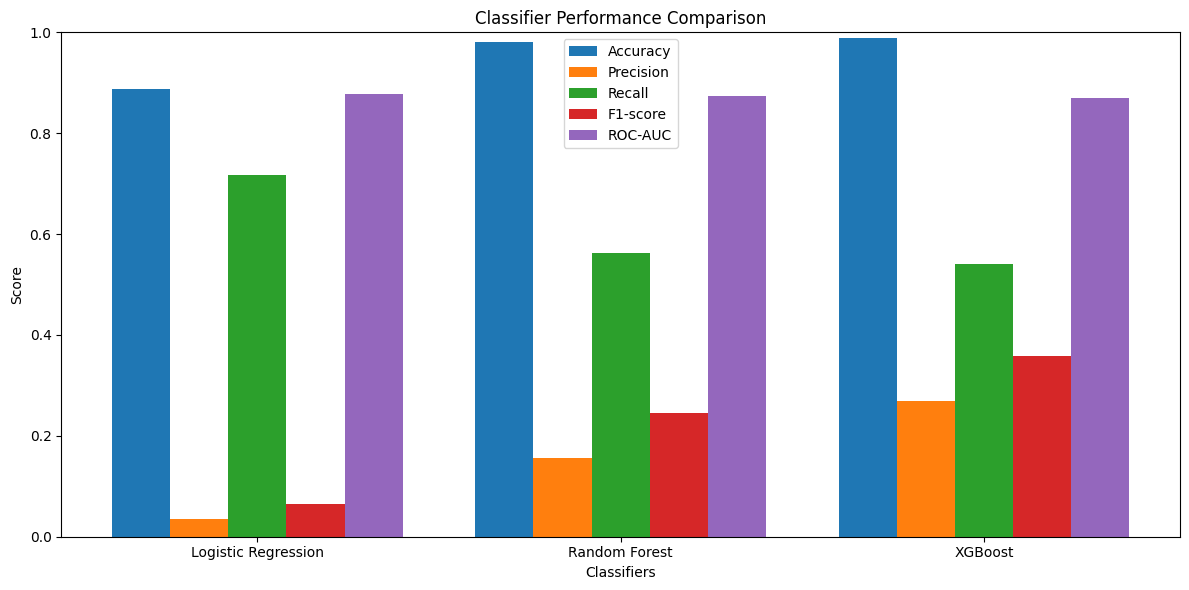

In [ ]:
# Cell 32A: Visualize the performance comparison of all three classifiers

import matplotlib.pyplot as plt
import numpy as np

models = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

accuracy = [lr_accuracy, rf_accuracy, xgb_accuracy]
precision = [lr_precision, rf_precision, xgb_precision]
recall = [lr_recall, rf_recall, xgb_recall]
f1 = [lr_f1, rf_f1, xgb_f1]
roc_auc = [lr_roc_auc, rf_roc_auc, xgb_roc_auc]

x = np.arange(len(models))
width = 0.16

plt.figure(figsize=(12, 6))

plt.bar(x - 2*width, accuracy, width, label="Accuracy")
plt.bar(x - width, precision, width, label="Precision")
plt.bar(x, recall, width, label="Recall")
plt.bar(x + width, f1, width, label="F1-score")
plt.bar(x + 2*width, roc_auc, width, label="ROC-AUC")

plt.xlabel("Classifiers")
plt.ylabel("Score")
plt.title("Classifier Performance Comparison")
plt.xticks(x, models)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

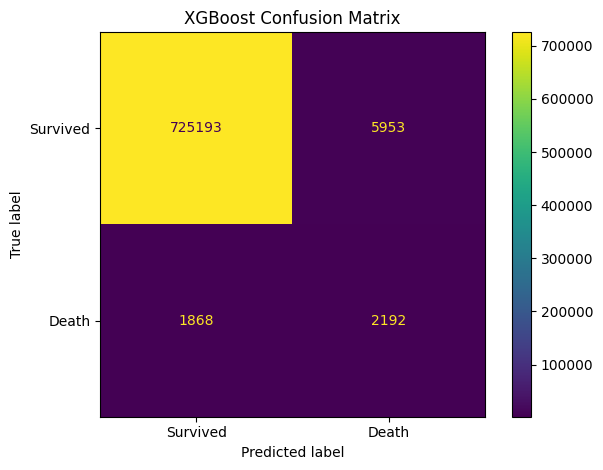

In [ ]:
# Cell 32B: Visualize the confusion matrix of the final XGBoost model

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=["Survived", "Death"]
)

plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

# Cell 33: Calculate training performance for all three models

In [ ]:
# Cell 33: Calculate training performance for all three models

# Logistic Regression predictions on balanced training data
y_train_pred_lr = lr_model.predict(X_train_lr)

# Random Forest predictions on balanced training data
y_train_pred_rf = rf_model.predict(X_train_balanced)

# XGBoost predictions on balanced training data
y_train_pred_xgb = xgb_model.predict(X_train_balanced)

# Calculate training accuracy
lr_train_accuracy = accuracy_score(y_train_balanced, y_train_pred_lr)
rf_train_accuracy = accuracy_score(y_train_balanced, y_train_pred_rf)
xgb_train_accuracy = accuracy_score(y_train_balanced, y_train_pred_xgb)

print("Training Accuracy")
print("-----------------")
print("Logistic Regression:", lr_train_accuracy)
print("Random Forest      :", rf_train_accuracy)
print("XGBoost            :", xgb_train_accuracy)

Training Accuracy
-----------------
Logistic Regression: 0.8413605600635568
Random Forest      : 0.9694492345782901
XGBoost            : 0.986477220443446


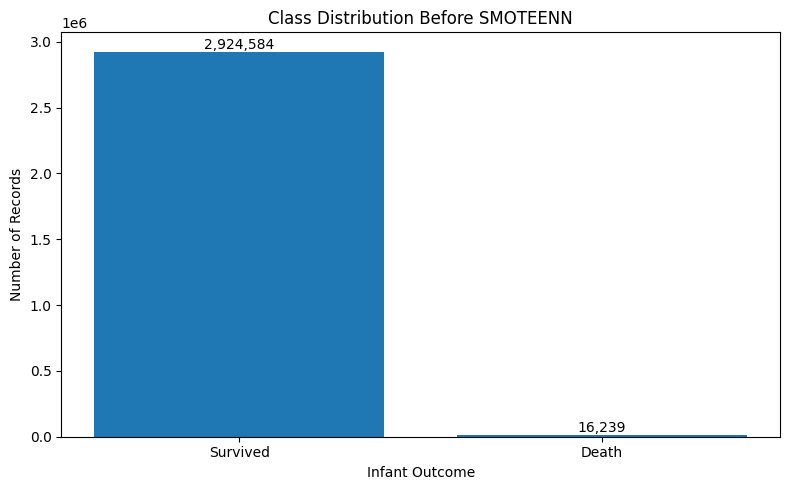

In [ ]:
# Cell 33: Visualize the class distribution of infant survival and infant death

import matplotlib.pyplot as plt

class_counts = y_train.value_counts().sort_index()

labels = ["Survived", "Death"]
values = [class_counts[0], class_counts[1]]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.xlabel("Infant Outcome")
plt.ylabel("Number of Records")
plt.title("Class Distribution Before SMOTEENN")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

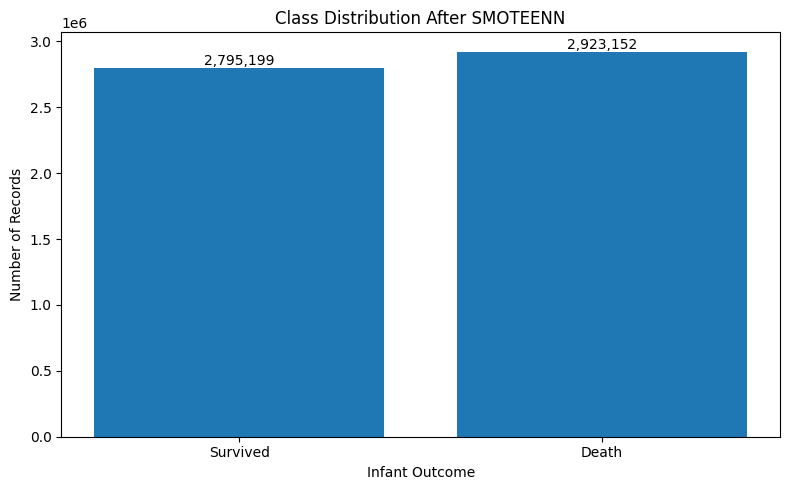

In [ ]:
# Cell 34: Visualize the class distribution after applying SMOTEENN

balanced_counts = y_train_balanced.value_counts().sort_index()

labels = ["Survived", "Death"]
values = [balanced_counts[0], balanced_counts[1]]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.xlabel("Infant Outcome")
plt.ylabel("Number of Records")
plt.title("Class Distribution After SMOTEENN")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# Cell 34: Compare training and test precision, recall, and F1-score

In [ ]:
# Cell 34: Compare training and test precision, recall, and F1-score

from sklearn.metrics import precision_score, recall_score, f1_score

# Training metrics
lr_train_precision = precision_score(y_train_balanced, y_train_pred_lr, zero_division=0)
lr_train_recall = recall_score(y_train_balanced, y_train_pred_lr, zero_division=0)
lr_train_f1 = f1_score(y_train_balanced, y_train_pred_lr, zero_division=0)

rf_train_precision = precision_score(y_train_balanced, y_train_pred_rf, zero_division=0)
rf_train_recall = recall_score(y_train_balanced, y_train_pred_rf, zero_division=0)
rf_train_f1 = f1_score(y_train_balanced, y_train_pred_rf, zero_division=0)

xgb_train_precision = precision_score(y_train_balanced, y_train_pred_xgb, zero_division=0)
xgb_train_recall = recall_score(y_train_balanced, y_train_pred_xgb, zero_division=0)
xgb_train_f1 = f1_score(y_train_balanced, y_train_pred_xgb, zero_division=0)

print("Training Performance")
print("--------------------")
print("Logistic Regression")
print("Precision:", lr_train_precision)
print("Recall   :", lr_train_recall)
print("F1-score :", lr_train_f1)

print("\nRandom Forest")
print("Precision:", rf_train_precision)
print("Recall   :", rf_train_recall)
print("F1-score :", rf_train_f1)

print("\nXGBoost")
print("Precision:", xgb_train_precision)
print("Recall   :", xgb_train_recall)
print("F1-score :", xgb_train_f1)

Training Performance
--------------------
Logistic Regression
Precision: 0.8901159591027624
Recall   : 0.7867941865493139
F1-score : 0.835272019544601

Random Forest
Precision: 0.9879928751973489
Recall   : 0.9518030536899894
F1-score : 0.9695603765661944

XGBoost
Precision: 0.9956075242263621
Recall   : 0.9778605423187026
F1-score : 0.9866542358407496


# Cell 37: Calculate and display feature importance from the trained XGBoost model


In [ ]:
# Cell 37: Calculate and display feature importance from the trained XGBoost model

xgb_importance = pd.DataFrame({
    "Feature": X_train_balanced.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

print("XGBoost Feature Importance")
print("--------------------------")
print(xgb_importance.to_string(index=False))

XGBoost Feature Importance
--------------------------
          Feature  Importance
           apgar5    0.310643
     birth_weight    0.115964
  prenatal_visits    0.113071
  gestational_age    0.105564
        education    0.077654
    gest_diabetes    0.064772
gest_hypertension    0.061235
       infant_sex    0.035139
 pre_hypertension    0.033834
        plurality    0.031951
       mother_age    0.017502
       cigarettes    0.017286
     pre_diabetes    0.013531
              bmi    0.001854


# Cell 38: Visualize the XGBoost feature importance

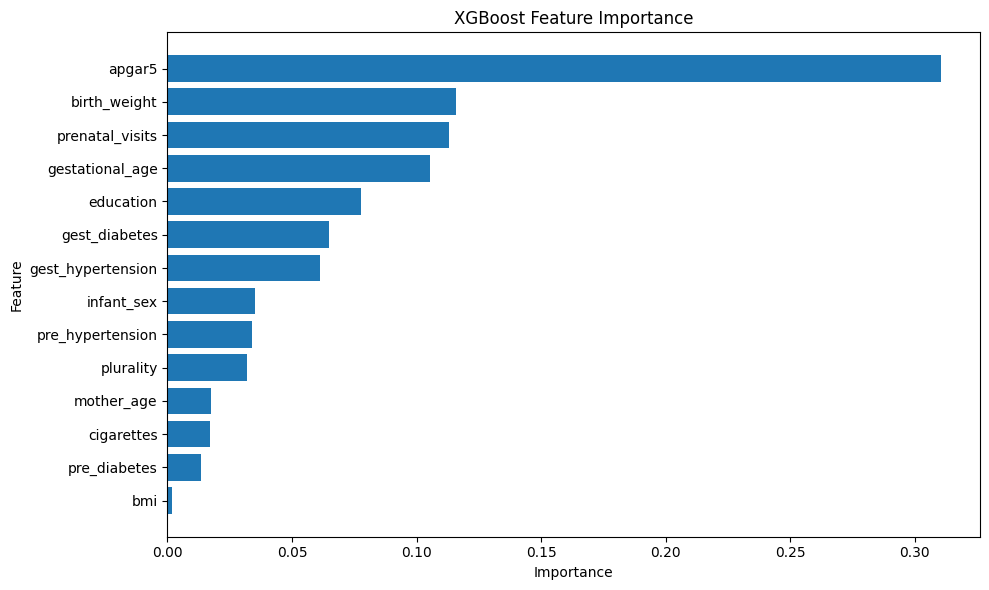

In [ ]:
# Cell 38: Visualize the XGBoost feature importance

plt.figure(figsize=(10, 6))

plt.barh(
    xgb_importance["Feature"],
    xgb_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Cell 39: Prepare the preprocessing information required for deployment


In [ ]:
# Cell 39: Prepare the preprocessing information required for deployment

import joblib
import os

# Exact feature order used during model training
feature_columns = [
    "mother_age",
    "education",
    "prenatal_visits",
    "cigarettes",
    "bmi",
    "pre_diabetes",
    "gest_diabetes",
    "pre_hypertension",
    "gest_hypertension",
    "apgar5",
    "plurality",
    "infant_sex",
    "gestational_age",
    "birth_weight"
]

# Calculate the median values used for imputation
median_values = {}

for col in feature_columns:
    median_values[col] = df[col].median()

print("Feature order:")
print(feature_columns)

print("\nMedian values:")
for col, value in median_values.items():
    print(f"{col}: {value}")

Feature order:
['mother_age', 'education', 'prenatal_visits', 'cigarettes', 'bmi', 'pre_diabetes', 'gest_diabetes', 'pre_hypertension', 'gest_hypertension', 'apgar5', 'plurality', 'infant_sex', 'gestational_age', 'birth_weight']

Median values:
mother_age: 30.0
education: 4.0
prenatal_visits: 11.0
cigarettes: 0.0
bmi: 26.4
pre_diabetes: 0.0
gest_diabetes: 0.0
pre_hypertension: 0.0
gest_hypertension: 0.0
apgar5: 9.0
plurality: 1.0
infant_sex: 1.0
gestational_age: 39.0
birth_weight: 3285.0


# Cell 40: Save the trained XGBoost model for Django deployment

In [ ]:
# Cell 40: Save the trained XGBoost model for Django deployment

model_path = "/content/drive/MyDrive/mini project dataset/xgb_infant_mortality_model.pkl"

joblib.dump(xgb_model, model_path)

print("XGBoost model saved successfully.")
print("Path:", model_path)

XGBoost model saved successfully.
Path: /content/drive/MyDrive/mini project dataset/xgb_infant_mortality_model.pkl


# Cell 41: Save the feature order and preprocessing information for deployment

In [ ]:
# Cell 41: Save the feature order and preprocessing information for deployment

preprocessing_info = {
    "feature_columns": feature_columns,
    "median_values": median_values,
    "disease_mapping": {
        "Y": 1,
        "N": 0,
        "U": None
    },
    "sex_mapping": {
        "M": 1,
        "F": 0
    },
    "unknown_codes": {
        "education": 9,
        "prenatal_visits": 99,
        "cigarettes": 99,
        "bmi": 99.9,
        "apgar5": 99,
        "gestational_age": 99,
        "birth_weight": 9999
    }
}

preprocessing_path = "/content/drive/MyDrive/mini project dataset/xgb_preprocessing.pkl"

joblib.dump(preprocessing_info, preprocessing_path)

print("Preprocessing information saved successfully.")
print("Path:", preprocessing_path)

Preprocessing information saved successfully.
Path: /content/drive/MyDrive/mini project dataset/xgb_preprocessing.pkl


# Cell 42: Verify that the saved model and preprocessing files can be loaded

In [ ]:
# Cell 42: Verify that the saved model and preprocessing files can be loaded

loaded_model = joblib.load(model_path)
loaded_preprocessing = joblib.load(preprocessing_path)

print("Model loaded successfully:", type(loaded_model).__name__)
print("Preprocessing information loaded successfully.")
print("Number of features:", len(loaded_preprocessing["feature_columns"]))

Model loaded successfully: XGBClassifier
Preprocessing information loaded successfully.
Number of features: 14


# Cell 43: Evaluate XGBoost at different classification thresholds


In [ ]:
# Cell 43: Evaluate XGBoost at different classification thresholds

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob_xgb >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold, zero_division=0),
        "Recall": recall_score(y_test, y_pred_threshold, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_threshold, zero_division=0)
    })
    print(confusion_matrix(y_test, y_pred_threshold))

threshold_results = pd.DataFrame(results)

print(threshold_results.to_string(index=False))

[[710358  20788]
 [  1541   2519]]
[[716000  15146]
 [  1613   2447]]
[[719335  11811]
 [  1682   2378]]
[[721519   9627]
 [  1729   2331]]
[[723035   8111]
 [  1785   2275]]
[[724275   6871]
 [  1826   2234]]
[[725193   5953]
 [  1868   2192]]
 Threshold  Accuracy  Precision   Recall  F1-score
      0.20  0.969629   0.108079 0.620443  0.184090
      0.25  0.977205   0.139089 0.602709  0.226019
      0.30  0.981647   0.167595 0.585714  0.260617
      0.35  0.984554   0.194932 0.574138  0.291048
      0.40  0.986540   0.219045 0.560345  0.314966
      0.45  0.988171   0.245360 0.550246  0.339385
      0.50  0.989362   0.269122 0.539901  0.359197


#Check using external data

In [ ]:
import joblib

preprocessing_path = "/content/drive/MyDrive/mini project dataset/xgb_preprocessing.pkl"

preprocessing = joblib.load(preprocessing_path)

print(type(preprocessing))
print("\nContents of preprocessing dictionary:")

for key, value in preprocessing.items():
    print(key, ":", type(value))

<class 'dict'>

Contents of preprocessing dictionary:
feature_columns : <class 'list'>
median_values : <class 'dict'>
disease_mapping : <class 'dict'>
sex_mapping : <class 'dict'>
unknown_codes : <class 'dict'>


In [ ]:
# ============================================================
# TEST SAVED XGBOOST MODEL WITH COMPLETELY NEW EXTERNAL DATA
# ============================================================

import pandas as pd
import numpy as np
import joblib


# ------------------------------------------------------------
# 1. Load the saved XGBoost model
# ------------------------------------------------------------

model_path = "/content/drive/MyDrive/mini project dataset/xgb_infant_mortality_model.pkl"

xgb_model = joblib.load(model_path)

print("XGBoost model loaded successfully:", type(xgb_model).__name__)


# ------------------------------------------------------------
# 2. Load the saved preprocessing information
# ------------------------------------------------------------

preprocessing_path = "/content/drive/MyDrive/mini project dataset/xgb_preprocessing.pkl"

preprocessing = joblib.load(preprocessing_path)

print("Preprocessing information loaded successfully.")


# ------------------------------------------------------------
# 3. Extract preprocessing information
# ------------------------------------------------------------

feature_columns = preprocessing["feature_columns"]
median_values = preprocessing["median_values"]
disease_mapping = preprocessing["disease_mapping"]
sex_mapping = preprocessing["sex_mapping"]
unknown_codes = preprocessing["unknown_codes"]

print("Number of features:", len(feature_columns))


# ------------------------------------------------------------
# 4. Create a completely NEW external case
# ------------------------------------------------------------

# external_data = {
#     "mother_age": 25,
#     "education": 6,
#     "prenatal_visits": 10,
#     "cigarettes": 0,
#     "bmi": 23.5,
#     "pre_diabetes": "N",
#     "gest_diabetes": "N",
#     "pre_hypertension": "N",
#     "gest_hypertension": "N",
#     "apgar5": 9,
#     "plurality": 1,
#     "infant_sex": "M",
#     "gestational_age": 39,
#     "birth_weight": 3200
# }

external_data = {
    "mother_age": 38,
    "education": 2,
    "prenatal_visits": 3,
    "cigarettes": 10,
    "bmi": 31.5,
    "pre_diabetes": "Y",
    "gest_diabetes": "Y",
    "pre_hypertension": "Y",
    "gest_hypertension": "Y",
    "apgar5": 3,
    "plurality": 2,
    "infant_sex": "M",
    "gestational_age": 27,
    "birth_weight": 900
}

new_data = pd.DataFrame([external_data])


# ------------------------------------------------------------
# 5. Arrange columns in the same order as training
# ------------------------------------------------------------

new_data = new_data[feature_columns]


# ------------------------------------------------------------
# 6. Replace CDC unknown codes with NaN
# ------------------------------------------------------------

for column, code in unknown_codes.items():

    if column in new_data.columns:
        new_data[column] = new_data[column].replace(code, np.nan)


# ------------------------------------------------------------
# 7. Convert disease columns using saved mapping
# ------------------------------------------------------------

for column, mapping in disease_mapping.items():

    if column in new_data.columns:
        new_data[column] = new_data[column].map(mapping)


# ------------------------------------------------------------
# 8. Convert infant sex using saved mapping
# ------------------------------------------------------------

for column, mapping in sex_mapping.items():

    if column in new_data.columns:
        new_data[column] = new_data[column].map(mapping)


# ------------------------------------------------------------
# 9. Convert all remaining columns to numeric
# ------------------------------------------------------------

for column in feature_columns:
    new_data[column] = pd.to_numeric(
        new_data[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# 10. Replace missing values using the SAVED medians
# ------------------------------------------------------------

for column in feature_columns:

    if column in median_values:

        new_data[column] = new_data[column].fillna(
            median_values[column]
        )


# ------------------------------------------------------------
# 11. Check the processed external data
# ------------------------------------------------------------

print("\nProcessed external data:")

print(new_data)

print("\nMissing values after preprocessing:")
print(new_data.isnull().sum().sum())


# ------------------------------------------------------------
# 12. Make prediction
# ------------------------------------------------------------

prediction = xgb_model.predict(new_data)

risk_probability = xgb_model.predict_proba(new_data)[0][1]


# ------------------------------------------------------------
# 13. Apply 0.50 classification threshold
# ------------------------------------------------------------

threshold = 0.50

if risk_probability >= threshold:
    risk_class = "High Risk"
else:
    risk_class = "Low Risk"


# ------------------------------------------------------------
# 14. Display final result
# ------------------------------------------------------------

print("\n==========================================")
print("    INFANT MORTALITY RISK PREDICTION")
print("==========================================")

print("Risk Probability :", f"{risk_probability:.4f}")
print("Risk Percentage  :", f"{risk_probability * 100:.2f}%")
print("Final Prediction :", risk_class)

print("==========================================")

XGBoost model loaded successfully: XGBClassifier
Preprocessing information loaded successfully.
Number of features: 14

Processed external data:
   mother_age  education  prenatal_visits  cigarettes   bmi  pre_diabetes  \
0          38          2                3          10  31.5           0.0   

   gest_diabetes  pre_hypertension  gest_hypertension  apgar5  plurality  \
0            0.0               0.0                0.0       3          2   

   infant_sex  gestational_age  birth_weight  
0         1.0               27           900  

Missing values after preprocessing:
0

    INFANT MORTALITY RISK PREDICTION
Risk Probability : 0.9575
Risk Percentage  : 95.75%
Final Prediction : High Risk


In [ ]:
# ============================================================
# TEST SAVED XGBOOST MODEL WITH COMPLETELY NEW EXTERNAL DATA
# ============================================================

import pandas as pd
import numpy as np
import joblib


# ------------------------------------------------------------
# 1. Load the saved XGBoost model
# ------------------------------------------------------------

model_path = "/content/drive/MyDrive/mini project dataset/xgb_infant_mortality_model.pkl"

xgb_model = joblib.load(model_path)

print("XGBoost model loaded successfully:", type(xgb_model).__name__)


# ------------------------------------------------------------
# 2. Load the saved preprocessing information
# ------------------------------------------------------------

preprocessing_path = "/content/drive/MyDrive/mini project dataset/xgb_preprocessing.pkl"

preprocessing = joblib.load(preprocessing_path)

print("Preprocessing information loaded successfully.")


# ------------------------------------------------------------
# 3. Extract preprocessing information
# ------------------------------------------------------------

feature_columns = preprocessing["feature_columns"]
median_values = preprocessing["median_values"]
disease_mapping = preprocessing["disease_mapping"]
sex_mapping = preprocessing["sex_mapping"]
unknown_codes = preprocessing["unknown_codes"]

print("Number of features:", len(feature_columns))


# ------------------------------------------------------------
# 4. Create a completely NEW external case
# ------------------------------------------------------------

external_data = {
    "mother_age": 25,
    "education": 6,
    "prenatal_visits": 10,
    "cigarettes": 0,
    "bmi": 23.5,
    "pre_diabetes": "N",
    "gest_diabetes": "N",
    "pre_hypertension": "N",
    "gest_hypertension": "N",
    "apgar5": 9,
    "plurality": 1,
    "infant_sex": "M",
    "gestational_age": 39,
    "birth_weight": 3200
}

# external_data = {
#     "mother_age": 38,
#     "education": 2,
#     "prenatal_visits": 3,
#     "cigarettes": 10,
#     "bmi": 31.5,
#     "pre_diabetes": "Y",
#     "gest_diabetes": "Y",
#     "pre_hypertension": "Y",
#     "gest_hypertension": "Y",
#     "apgar5": 3,
#     "plurality": 2,
#     "infant_sex": "M",
#     "gestational_age": 27,
#     "birth_weight": 900
# }

new_data = pd.DataFrame([external_data])


# ------------------------------------------------------------
# 5. Arrange columns in the same order as training
# ------------------------------------------------------------

new_data = new_data[feature_columns]


# ------------------------------------------------------------
# 6. Replace CDC unknown codes with NaN
# ------------------------------------------------------------

for column, code in unknown_codes.items():

    if column in new_data.columns:
        new_data[column] = new_data[column].replace(code, np.nan)


# ------------------------------------------------------------
# 7. Convert disease columns using saved mapping
# ------------------------------------------------------------

for column, mapping in disease_mapping.items():

    if column in new_data.columns:
        new_data[column] = new_data[column].map(mapping)


# ------------------------------------------------------------
# 8. Convert infant sex using saved mapping
# ------------------------------------------------------------

for column, mapping in sex_mapping.items():

    if column in new_data.columns:
        new_data[column] = new_data[column].map(mapping)


# ------------------------------------------------------------
# 9. Convert all remaining columns to numeric
# ------------------------------------------------------------

for column in feature_columns:
    new_data[column] = pd.to_numeric(
        new_data[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# 10. Replace missing values using the SAVED medians
# ------------------------------------------------------------

for column in feature_columns:

    if column in median_values:

        new_data[column] = new_data[column].fillna(
            median_values[column]
        )


# ------------------------------------------------------------
# 11. Check the processed external data
# ------------------------------------------------------------

print("\nProcessed external data:")

print(new_data)

print("\nMissing values after preprocessing:")
print(new_data.isnull().sum().sum())


# ------------------------------------------------------------
# 12. Make prediction
# ------------------------------------------------------------

prediction = xgb_model.predict(new_data)

risk_probability = xgb_model.predict_proba(new_data)[0][1]


# ------------------------------------------------------------
# 13. Apply 0.50 classification threshold
# ------------------------------------------------------------

threshold = 0.50

if risk_probability >= threshold:
    risk_class = "High Risk"
else:
    risk_class = "Low Risk"


# ------------------------------------------------------------
# 14. Display final result
# ------------------------------------------------------------

print("\n==========================================")
print("    INFANT MORTALITY RISK PREDICTION")
print("==========================================")

print("Risk Probability :", f"{risk_probability:.4f}")
print("Risk Percentage  :", f"{risk_probability * 100:.2f}%")
print("Final Prediction :", risk_class)

print("==========================================")

XGBoost model loaded successfully: XGBClassifier
Preprocessing information loaded successfully.
Number of features: 14

Processed external data:
   mother_age  education  prenatal_visits  cigarettes   bmi  pre_diabetes  \
0          25          6               10           0  23.5           0.0   

   gest_diabetes  pre_hypertension  gest_hypertension  apgar5  plurality  \
0            0.0               0.0                0.0       9          1   

   infant_sex  gestational_age  birth_weight  
0         1.0               39          3200  

Missing values after preprocessing:
0

    INFANT MORTALITY RISK PREDICTION
Risk Probability : 0.0111
Risk Percentage  : 1.11%
Final Prediction : Low Risk


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Titanic.csv to Titanic.csv


In [ ]:
import pandas as pd

df = pd.read_csv("Titanic.csv")
print(df.head(3))
print("\n")
print(df.columns)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [ ]:
import pandas as pd

df = pd.read_csv("Titanic.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

First 5 rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN

In [ ]:
# Select features and target
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
y = df['Survived']

# Handle missing values
X['Age'] = X['Age'].fillna(X['Age'].median())
X['Embarked'] = X['Embarked'].fillna(X['Embarked'].mode()[0])

# Encode categorical data
X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
X['Embarked'] = X['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

print("Preprocessed Data:")
print(X.head())

print("\nMissing Values After Preprocessing:")
print(X.isnull().sum())

Preprocessed Data:
   Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0       3    0  22.0      1      0   7.2500         0
1       1    1  38.0      1      0  71.2833         1
2       3    1  26.0      0      0   7.9250         0
3       1    1  35.0      1      0  53.1000         0
4       3    0  35.0      0      0   8.0500         0

Missing Values After Preprocessing:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


In [ ]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100,2), "%")

Accuracy: 82.12 %


Confusion Matrix:
[[97 13]
 [19 50]]


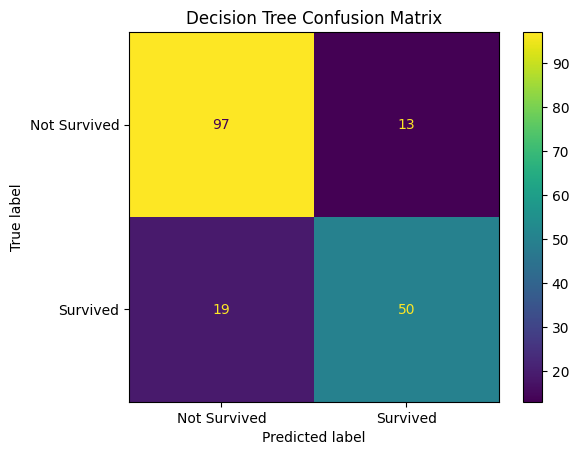

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Survived", "Survived"]
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Survived", "Survived"]
))

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.84      0.88      0.86       110
    Survived       0.79      0.72      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



In [ ]:
import pandas as pd

feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
Sex         0.316638
Age         0.270281
Fare        0.232792
Pclass      0.110281
Embarked    0.034104
SibSp       0.019053
Parch       0.016851
dtype: float64


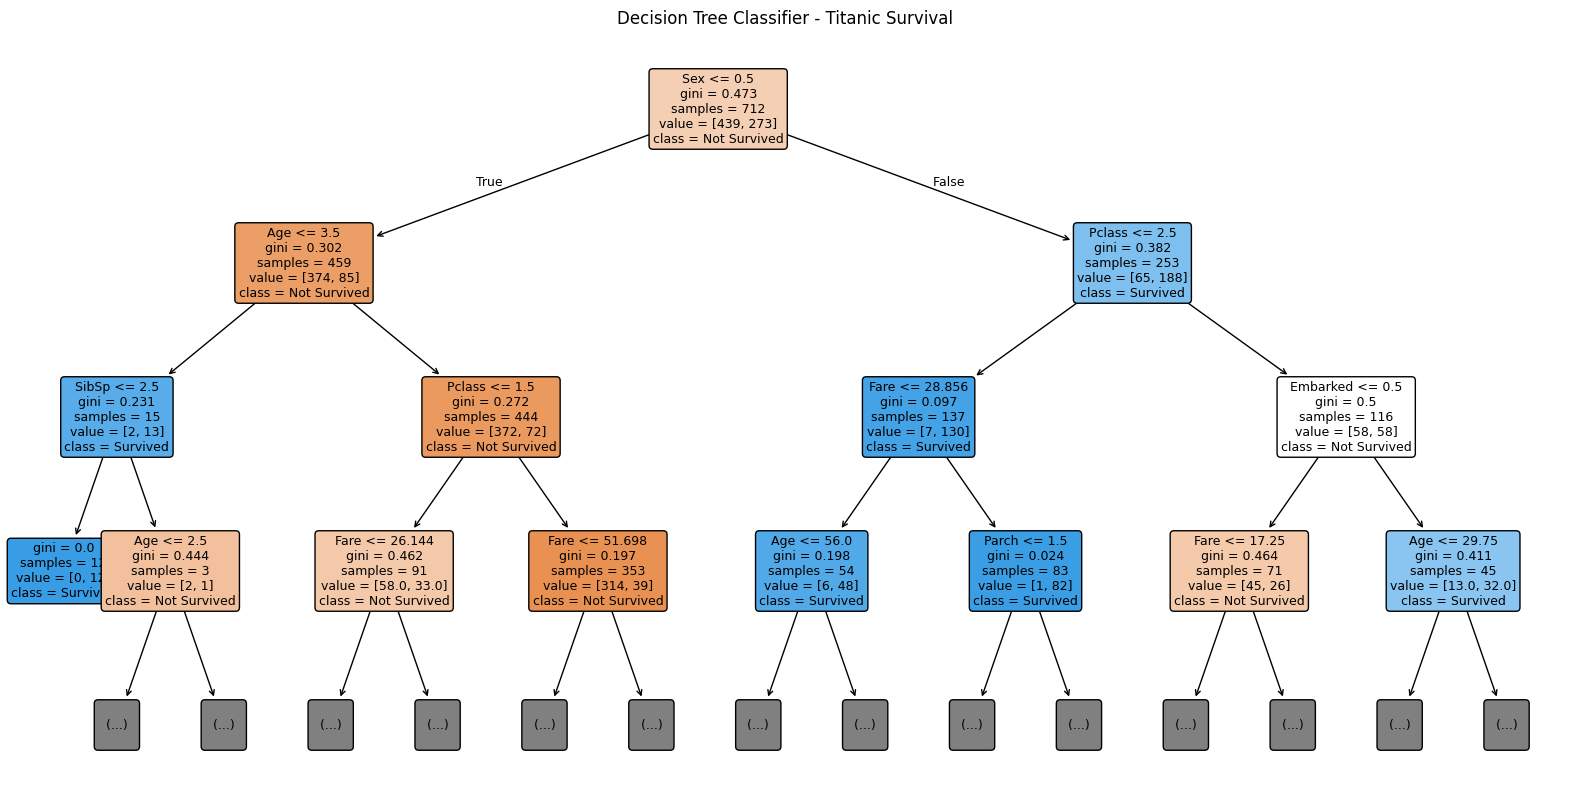

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Not Survived", "Survived"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Classifier - Titanic Survival")

plt.show()